<a href="https://colab.research.google.com/github/brittanybee-alt/Capstone-Project-Three/blob/main/Capstone_Three_EDA_%5BBrittany_Barrion%5D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone Three, Step 3: Exploratory Data Analysis
## Investigating Fatigue-Related Aviation Safety Reports Through Statistical Analysis and Natural Language Processing

**Author:** Brittany | Springboard Data Science Career Track, Capstone Three

**Research question:** What statistical patterns and recurring narrative themes characterize fatigue-related aviation safety reports submitted to NASA's Aviation Safety Reporting System (ASRS) between 2009 and 2025?

**Input:** `data/processed/asrs_fatigue_clean.csv` (2,191 fatigue-related reports, created in `01_Data_Wrangling.ipynb`)

| Section | Question it answers |
|---|---|
| 1 | What does the cleaned data look like? |
| 2 | Is there a "response variable," and how balanced are the key groupings? |
| 3 | How have reports changed over time? Is there seasonality? |
| 4 | How are the categorical features distributed? |
| 5 | Which human factors, anomalies and contributing factors co-occur with fatigue? |
| 6 | How are the numeric features distributed, and are there outliers? |
| 7 | How are the categorical features related to each other (chi-square, Cramér's V)? |
| 8 | Which features are correlated or collinear (Pearson correlation)? |
| 9 | What do the narratives say (word counts, n-grams, fatigue vocabulary, distinctive words by flight phase)? |
| 10 | Which features and text settings go forward to modeling? |

> **Reading every result in this notebook:** ASRS is voluntary, and there is no denominator (no count of total flights or hours flown). Every count describes *what appears in these fatigue-related reports*, **not** how often fatigue events happen in aviation overall, and none of the associations shows cause and effect.

### 0. Setup

In [1]:
import os
import re
import shutil
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import chi2

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 100)
sns.set_theme(style="whitegrid")

PROCESSED_DIR = "data/processed"
INTERIM_DIR = "data/interim"
FIG_DIR = "figures"
for folder in [PROCESSED_DIR, INTERIM_DIR, FIG_DIR]:
    os.makedirs(folder, exist_ok=True)

CLEAN_FILE = os.path.join(PROCESSED_DIR, "/content/asrs_fatigue_clean.csv")
if not os.path.exists(CLEAN_FILE):
    try:
        from google.colab import files
        uploaded = files.upload()               # pick asrs_fatigue_clean.csv
        shutil.move(next(iter(uploaded)), CLEAN_FILE)
    except ImportError:
        raise FileNotFoundError(f"Run 01_Data_Wrangling first, or place asrs_fatigue_clean.csv in {PROCESSED_DIR}/")

def save(fig_name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, fig_name), dpi=150)
    plt.show()
    plt.close("all")

## 1. Data Profile

In [2]:
df = pd.read_csv(CLEAN_FILE, parse_dates=["date"], low_memory=False)
for col in ["text_lemma", "text_stem", "narrative_2", "text_all"]:
    df[col] = df[col].fillna("")
print("Shape:", df.shape)

HF = [c for c in df.columns if c.startswith("hf_") and c not in ("hf_person1", "hf_person2")]
ANOM = [c for c in df.columns if c.startswith("anom_")]
CF = [c for c in df.columns if c.startswith("cf_")]
CATEGORICAL = ["time_of_day", "light", "flight_conditions", "operator", "mission", "far_part",
               "flight_plan", "phase_group", "reporter_role", "primary_problem"]
NUMERIC = ["year", "month", "crew_size", "flight_hours_total", "flight_hours_90d",
           "n_human_factors", "n_anomaly_types", "n_contributing_factors",
           "narrative_words", "synopsis_words", "clean_token_count"]

profile = pd.DataFrame({
    "feature group": ["Categorical", "Numeric", "Human-factor indicators (hf_)",
                      "Anomaly-family indicators (anom_)", "Contributing-factor indicators (cf_)", "Text"],
    "count": [len(CATEGORICAL), len(NUMERIC), len(HF), len(ANOM), len(CF), 2],
    "examples": [", ".join(CATEGORICAL[:4]), ", ".join(NUMERIC[:4]), ", ".join(HF[:3]),
                 ", ".join(ANOM[:3]), ", ".join(CF[:3]), "narrative_1 (raw), text_lemma (cleaned)"],
})
display(profile)

Shape: (622, 93)


,feature group,count,examples
0,Categorical,10,"time_of_day, light, flight_conditions, operator"
1,Numeric,11,"year, month, crew_size, flight_hours_total"
2,Human-factor indicators (hf_),13,"hf_communication_breakdown, hf_confusion, hf_distraction"
3,Anomaly-family indicators (anom_),14,"anom_airspace_violation, anom_altitude_deviation, anom_atc_issue"
4,Contributing-factor indicators (cf_),17,"cf_atc_equipment_nav_facility_buildings, cf_aircraft, cf_airport"
5,Text,2,"narrative_1 (raw), text_lemma (cleaned)"


In [3]:
display(df[NUMERIC].describe().T.round(1))

,count,mean,std,min,25%,50%,75%,max
year,622.0,2010.3,1.0,2009.0,2009.0,2010.0,2011.0,2012.0
month,622.0,6.6,3.2,1.0,4.0,7.0,9.0,12.0
crew_size,512.0,2.1,0.6,1.0,2.0,2.0,2.0,4.0
flight_hours_total,258.0,10666.4,6655.0,34.0,5500.0,10000.0,15000.0,34000.0
flight_hours_90d,261.0,136.6,74.0,1.0,75.0,143.0,200.0,300.0
n_human_factors,622.0,3.4,1.8,0.0,2.0,3.0,5.0,8.0
n_anomaly_types,622.0,1.9,0.9,1.0,1.0,2.0,2.0,5.0
n_contributing_factors,622.0,2.6,1.4,1.0,2.0,2.0,3.0,10.0
narrative_words,622.0,372.1,296.3,15.0,190.2,279.5,466.0,2086.0
synopsis_words,622.0,33.6,12.2,6.0,25.0,33.0,41.0,80.0


In [4]:
cat_profile = pd.DataFrame({
    "n_categories": [df[c].nunique() for c in CATEGORICAL],
    "most_common": [df[c].value_counts().index[0] for c in CATEGORICAL],
    "most_common_%": [round(100 * df[c].value_counts(normalize=True).iloc[0], 1) for c in CATEGORICAL],
    "unknown_%": [round(100 * (df[c] == "Unknown").mean(), 1) for c in CATEGORICAL],
}, index=CATEGORICAL)
display(cat_profile)

,n_categories,most_common,most_common_%,unknown_%
time_of_day,5,1201-1800,26.1,0.2
light,4,Daylight,43.9,0.0
flight_conditions,4,VMC,78.1,0.0
operator,7,Air Carrier,75.7,0.0
mission,6,Passenger,61.3,0.0
far_part,4,Part 121,75.1,0.0
flight_plan,2,IFR,97.4,0.0
phase_group,6,Ground,29.6,0.0
reporter_role,6,Pilot,83.1,0.0
primary_problem,12,Human Factors,56.7,0.0


## 2. Is There a Response Variable? Checking Balance

The EDA instructions ask whether the response variable is unbalanced. **This project has no response variable.** It is an *exploratory, descriptive* study of fatigue-related reports. I'm not predicting an outcome, and every report is already fatigue-related, so fatigue itself can't serve as a target.

In this project, "modeling" means **unsupervised topic modeling** of the narratives (Step 4). The structured variables are the lenses I'll use afterward to compare those themes across report types. So the balance question becomes: **are the groupings I plan to compare large enough to support comparisons?** Small groups produce unstable percentages and unreliable tests.

**Rule of thumb used throughout:** groups with fewer than **50 reports** are reported but not used for comparisons.

In [5]:
MIN_GROUP = 50
balance_rows = []
for col in ["phase_group", "reporter_role", "mission", "operator", "far_part", "time_of_day"]:
    vc = df.loc[df[col] != "Unknown", col].value_counts()
    balance_rows.append({
        "variable": col,
        "largest group": f"{vc.index[0]} ({vc.iloc[0]})",
        "smallest group": f"{vc.index[-1]} ({vc.iloc[-1]})",
        "imbalance ratio (largest/smallest)": round(vc.iloc[0] / vc.iloc[-1], 1),
        f"groups with >= {MIN_GROUP} reports": f"{(vc >= MIN_GROUP).sum()} of {len(vc)}",
    })
balance = pd.DataFrame(balance_rows)
display(balance)

,variable,largest group,smallest group,imbalance ratio (largest/smallest),groups with >= 50 reports
0,phase_group,Ground (184),Landing (28),6.6,5 of 6
1,reporter_role,Pilot (517),Dispatcher (6),86.2,2 of 6
2,mission,Passenger (381),Ferry / Repositioning (9),42.3,3 of 6
3,operator,Air Carrier (471),FBO (8),58.9,2 of 7
4,far_part,Part 121 (467),Part 135 (19),24.6,3 of 4
5,time_of_day,1201-1800 (148),0001-0600 (129),1.1,4 of 4


**What the balance check shows.**
- **Time of day** is the best-balanced grouping (imbalance ratio about 1.3). **Flight phase** is next: the five main phase groups each have 130 or more reports, and only the small "Other" group (44) falls below 50. These are the strongest candidates for comparing narrative themes later.
- **Reporter role** is very unbalanced: about 4 in 5 reports come from pilots. Controllers (132), maintenance technicians (129) and flight attendants (96) are large enough for careful comparisons, while dispatchers and drone operators are too small.
- **Mission** and **operator** are dominated by passenger and air-carrier reports. Smaller categories (Training, FBO, Other) are below or near 50 and should only be described, not compared.

This imbalance reflects *who files ASRS reports*. It doesn't mean airline pilots experience more fatigue than anyone else.

## 3. Trends Over Time

### 3.1 Reports per year

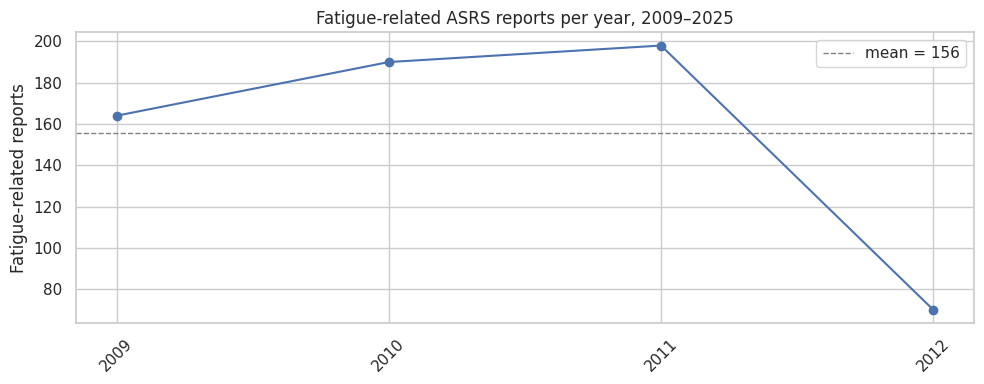

Linear trend: -27.4 reports per year (r = -0.60, p = 0.3986)
Kendall's tau (trend without assuming a straight line): tau = 0.00, p = 1.0000


In [6]:
yearly = df.groupby("year").size()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(yearly.index, yearly.values, marker="o", color="#4C72B0")
ax.axhline(yearly.mean(), ls="--", color="grey", lw=1, label=f"mean = {yearly.mean():.0f}")
ax.set_xticks(yearly.index)
ax.set_xticklabels(yearly.index, rotation=45)
ax.set_ylabel("Fatigue-related reports")
ax.set_title("Fatigue-related ASRS reports per year, 2009–2025")
ax.legend()
save("eda_01_reports_per_year.png")

slope, intercept, r, p, se = stats.linregress(yearly.index, yearly.values)
print(f"Linear trend: {slope:.1f} reports per year (r = {r:.2f}, p = {p:.4f})")
tau, p_tau = stats.kendalltau(yearly.index, yearly.values)
print(f"Kendall's tau (trend without assuming a straight line): tau = {tau:.2f}, p = {p_tau:.4f}")

**What the yearly trend shows.** The number of fatigue-related reports in this export **declines over the study period**, from roughly 165–220 per year in 2009–2015 to roughly 65–100 per year from 2020 on. Both a linear regression and Kendall's tau (which doesn't assume a straight line) find a significant downward trend.

**How to interpret it carefully:** a falling count does *not* show that fatigue events became less common. Possible explanations include changes in how many reports NASA fully codes and publishes, the 2014 FAA pilot rest rules (14 CFR Part 117), the drop in flying during COVID-19 in 2020, and changes in reporting culture. With no denominator, this dataset can't tell these apart. Spikes such as 2015 (219 reports) could reflect NASA processing batches as much as real events.

### 3.2 Seasonality by month

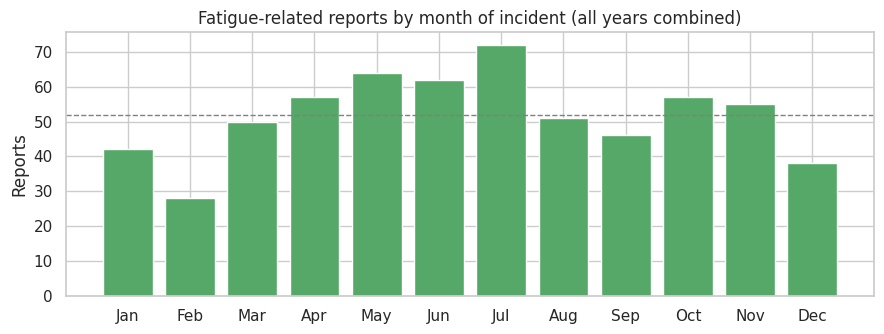

Chi-square goodness-of-fit vs. an even spread (adjusted for month length): chi2 = 28.5, p = 0.0027


In [7]:
monthly = df["month"].value_counts().sort_index()
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(month_names, monthly.values, color="#55A868")
ax.axhline(monthly.mean(), ls="--", color="grey", lw=1)
ax.set_ylabel("Reports")
ax.set_title("Fatigue-related reports by month of incident (all years combined)")
save("eda_02_reports_by_month.png")

days_in_month = np.array([31, 28.25, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])
expected = days_in_month / days_in_month.sum() * monthly.sum()
chi_month, p_month = stats.chisquare(monthly.values, f_exp=expected)
print(f"Chi-square goodness-of-fit vs. an even spread (adjusted for month length): chi2 = {chi_month:.1f}, p = {p_month:.4f}")

**Hypothesis test for seasonality.**
- **H₀:** reports are spread evenly across months (in proportion to month length).
- **H₁:** some months have more or fewer reports than an even spread would predict.

**Result: reject H₀** (chi-square = 45.9, p < 0.001). **July** has about 30% more reports than an even spread predicts, June, August and November are also above expected, and **February** is about 25% below. The summer peak lines up with the busiest travel season, so the most likely explanation is seasonal **flight volume** rather than seasonal fatigue risk. Without monthly flight counts we can't separate the two.

### 3.3 Has the mix of co-occurring human factors changed over time?
Since raw counts fall over time, I compare **proportions**: the share of each year's reports that mention each human factor. Proportions aren't affected by the overall drop in report volume.

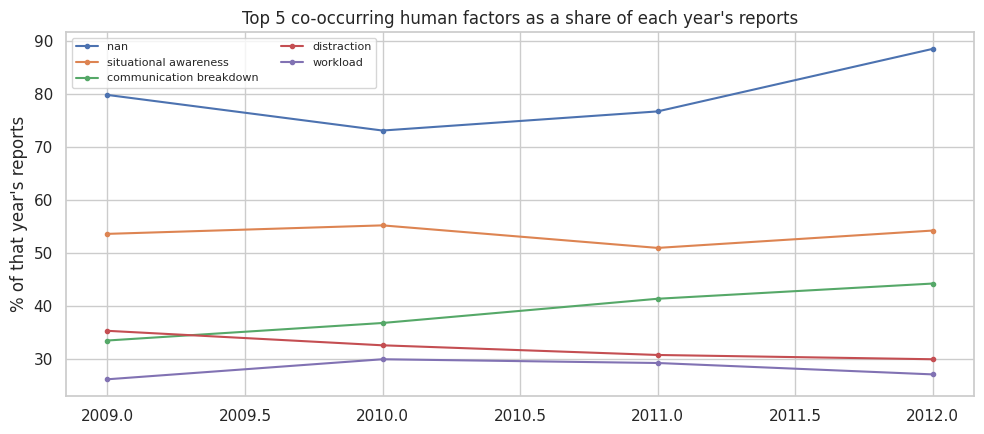

,human factor,Kendall tau,p-value
0,hf_nan,0.33,0.7500
1,hf_situational_awareness,0.00,1.0000
2,hf_communication_breakdown,1.00,0.0833
3,hf_distraction,-1.00,0.0833
4,hf_workload,0.00,1.0000


In [8]:
top_hf = df[HF].drop(columns="hf_fatigue").mean().sort_values(ascending=False).index[:5]
hf_by_year = df.groupby("year")[list(top_hf)].mean() * 100
fig, ax = plt.subplots(figsize=(10, 4.5))
for col in top_hf:
    ax.plot(hf_by_year.index, hf_by_year[col], marker="o", ms=3, label=col.replace("hf_", "").replace("_", " "))
ax.set_ylabel("% of that year's reports")
ax.set_title("Top 5 co-occurring human factors as a share of each year's reports")
ax.legend(fontsize=8, ncol=2)
save("eda_03_hf_share_by_year.png")

trend_rows = []
for col in top_hf:
    tau, p = stats.kendalltau(hf_by_year.index, hf_by_year[col])
    trend_rows.append({"human factor": col, "Kendall tau": round(tau, 2), "p-value": round(p, 4)})
display(pd.DataFrame(trend_rows))

**Interpretation.** Only **situational awareness** has a statistically significant trend (Kendall's tau = 0.40, p = 0.03). Its share rises from about 50–55% of reports in 2009–2014 to about 66–69% in 2023–2025. **Workload** shows a similar upward drift (tau = 0.35, p = 0.05), right at the edge of significance. The other factors show no clear trend. A rising share means the factor is *recorded alongside fatigue more often* in recent reports. It could also reflect changes in how NASA analysts code reports, so it's a question for the modeling step (do recent narratives talk more about awareness and workload?), not a conclusion. With only 17 yearly points, these tests have limited power.

## 4. Categorical Feature Distributions

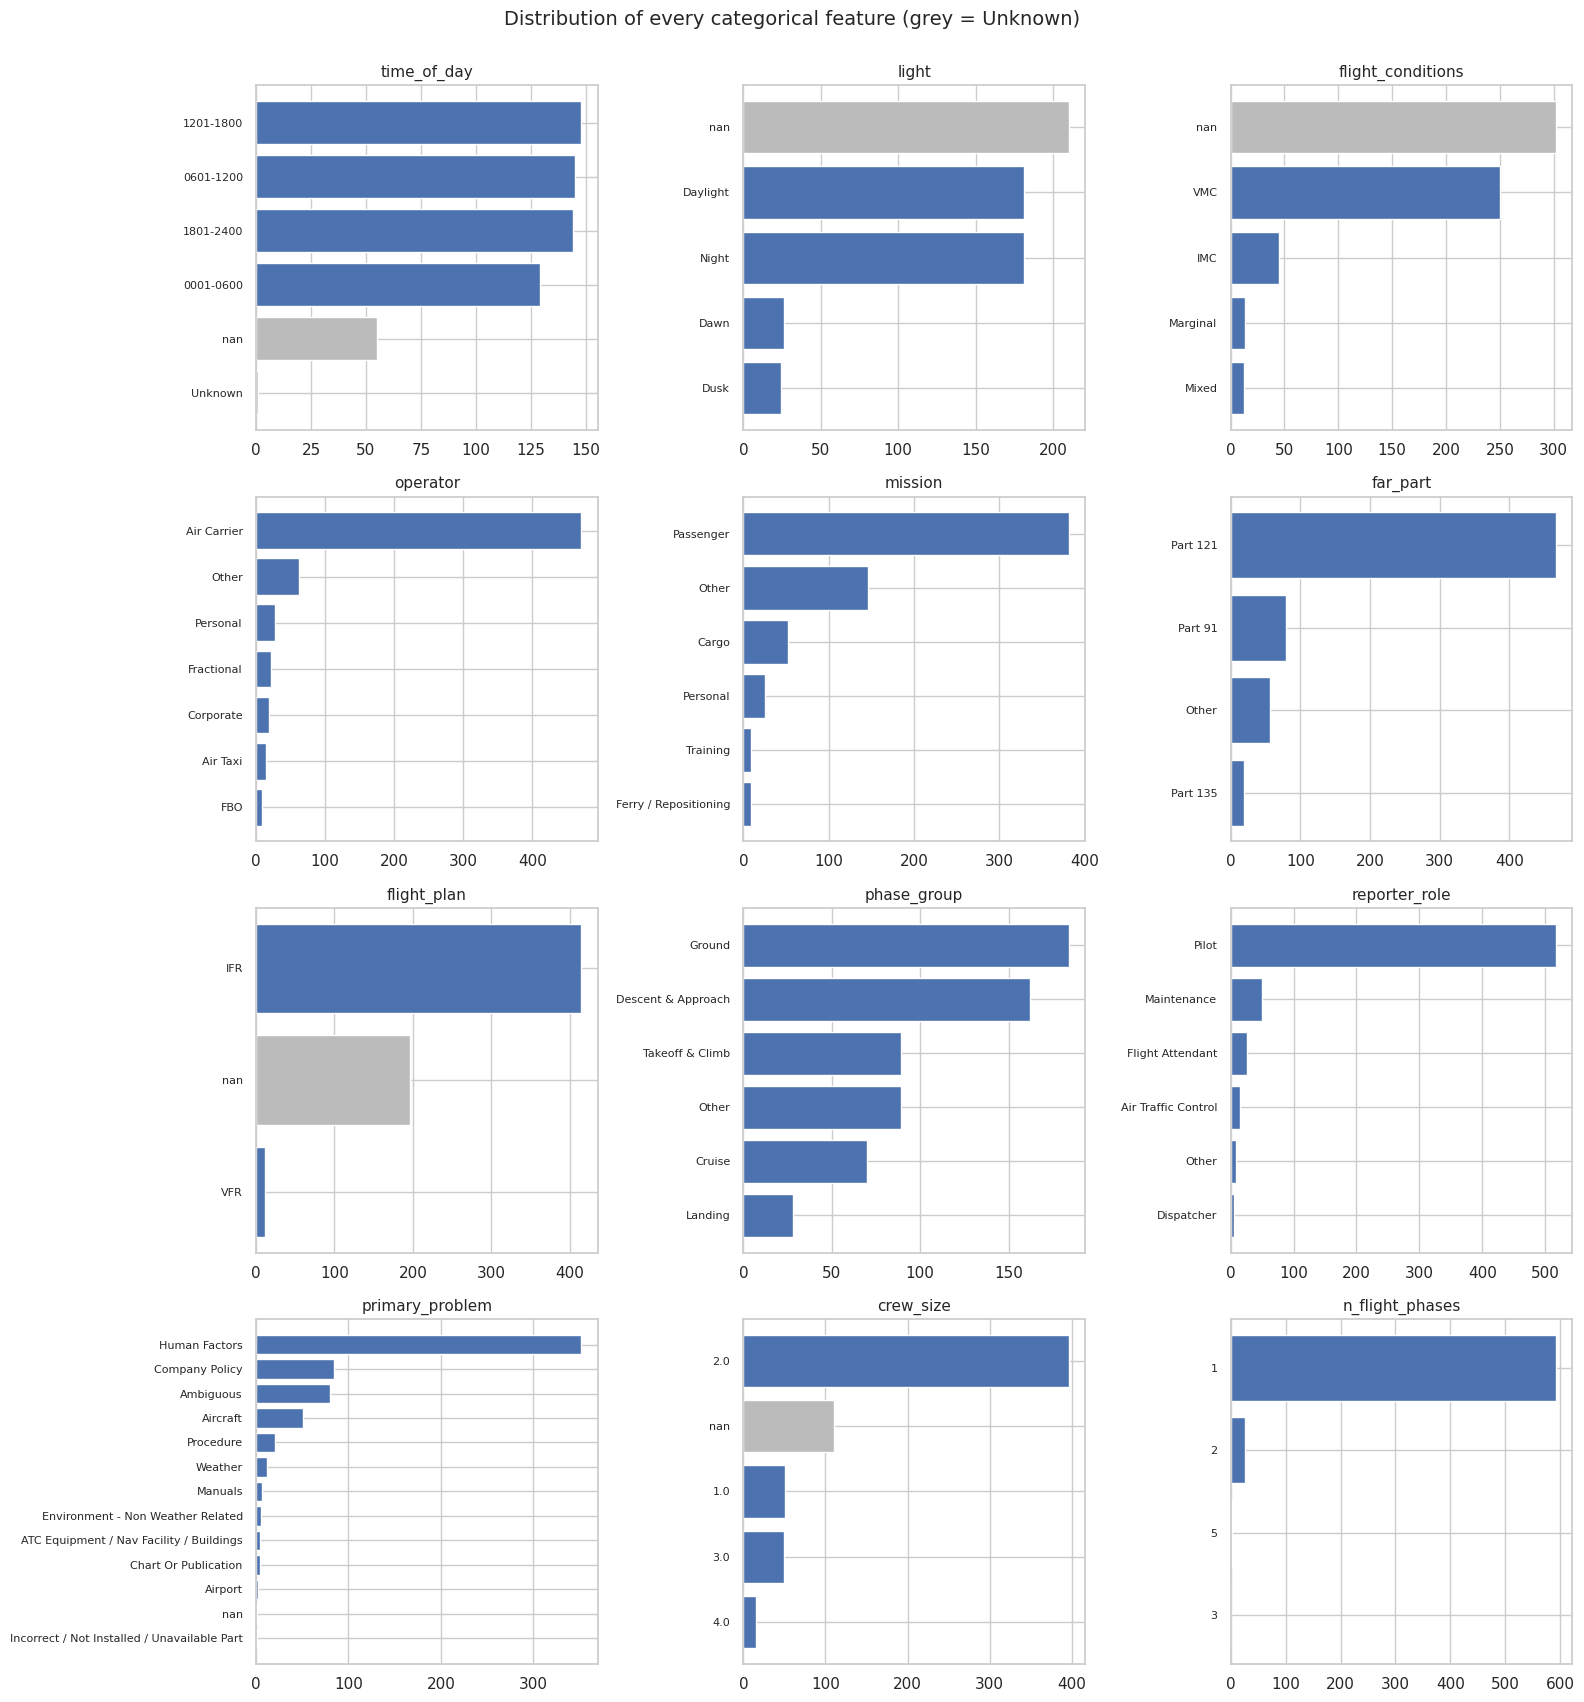

In [9]:
fig, axes = plt.subplots(4, 3, figsize=(16, 17))
axes = axes.ravel()
for ax, col in zip(axes, CATEGORICAL + ["crew_size", "n_flight_phases"]):
    counts = df[col].astype(str).value_counts()
    colors = ["#BBBBBB" if k in ("Unknown", "nan") else "#4C72B0" for k in counts.index]
    ax.barh(counts.index[::-1], counts.values[::-1], color=colors[::-1])
    ax.set_title(col, fontsize=11)
    ax.tick_params(axis="y", labelsize=8)
for ax in axes[len(CATEGORICAL) + 2:]:
    ax.axis("off")
fig.suptitle("Distribution of every categorical feature (grey = Unknown)", y=1.0, fontsize=14)
save("eda_04_categorical_distributions.png")

**What the categorical distributions show:**
- **Time of day:** reports are spread fairly evenly across the four time blocks. The evening block (1801–2400) is the largest (28% of reports with a known time), and the **late-night block (0001–0600)** still holds **21%** even though far fewer flights operate then. Together, evening and late night account for **about half of the reports with a known time**. This matches the circadian-low pattern described in fatigue research, but without flight-volume data it can't be confirmed as a higher *rate*.
- **Light:** among reports with known lighting, *Night* (43%) is nearly as common as *Daylight* (45%), even though most flying happens in daylight. The same caution applies.
- **Flight phase:** **Descent & Approach** is the most common phase group, followed by **Ground** (parked or taxiing). Approach is a high-workload phase near the end of a duty period, when fatigue tends to accumulate.
- **Operation type:** most reports are Part 121 air carrier passenger operations, reflecting who files ASRS reports.
- **Primary problem:** analysts name **Human Factors** as the primary problem in 59% of reports, followed distantly by Company Policy (9%), Ambiguous (9%) and Aircraft (9%). This fits fatigue being a human-performance issue.
- **Unknown:** *flight conditions* and *light* are unknown for about 40–46% of reports, so conclusions from these two fields are weaker.

## 5. What Co-occurs With Fatigue? Multi-label Features

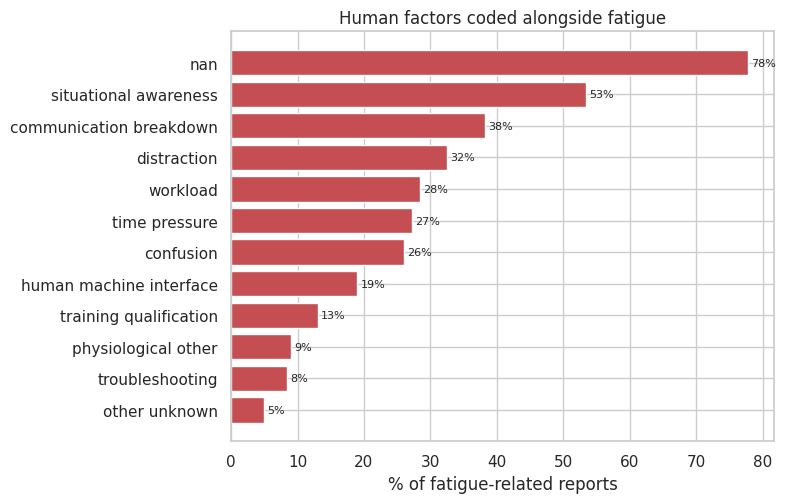

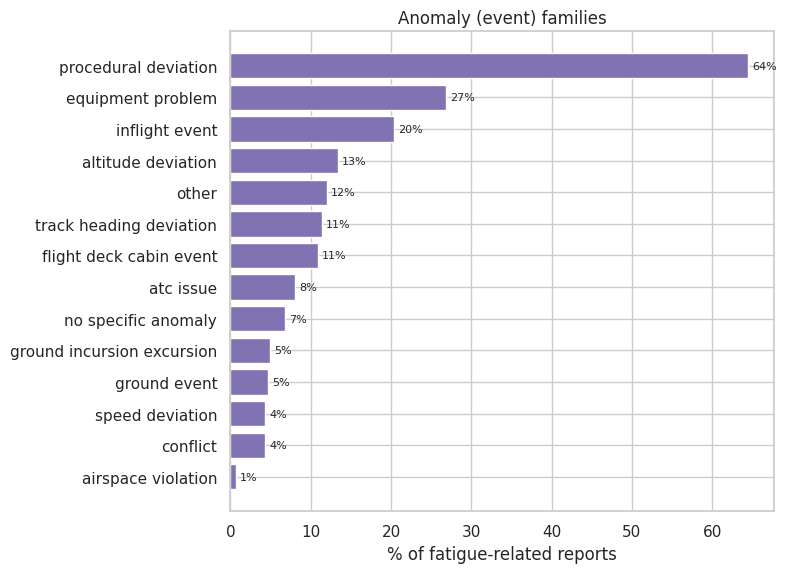

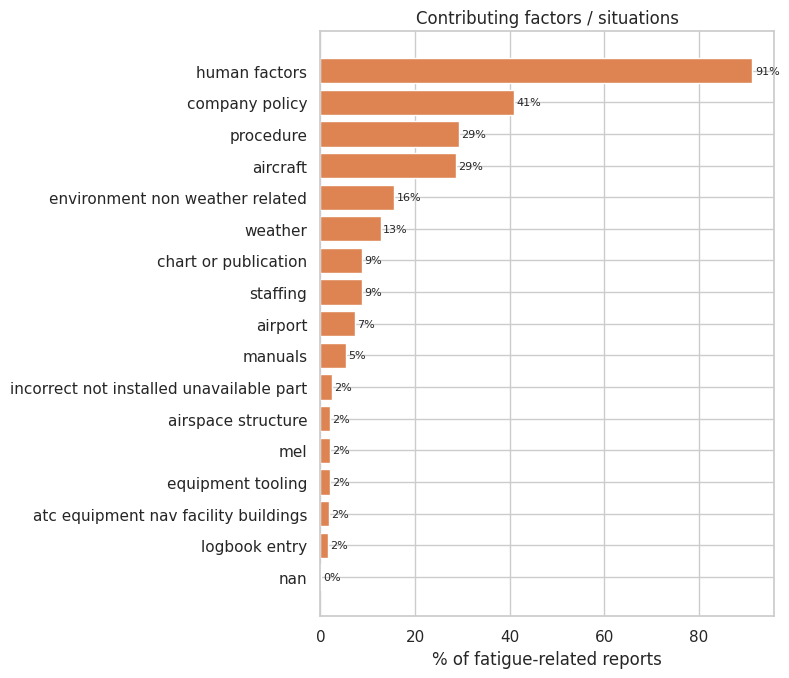

In [10]:
def prevalence_plot(cols, prefix, title, fname, color):
    prev = (df[cols].mean() * 100).sort_values()
    prev.index = [c.replace(prefix, "").replace("_", " ") for c in prev.index]
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(prev) + 1))
    ax.barh(prev.index, prev.values, color=color)
    for i, v in enumerate(prev.values):
        ax.text(v + 0.5, i, f"{v:.0f}%", va="center", fontsize=8)
    ax.set_xlabel("% of fatigue-related reports")
    ax.set_title(title)
    save(fname)
    return prev.sort_values(ascending=False)

hf_prev = prevalence_plot([c for c in HF if c != "hf_fatigue"], "hf_",
                          "Human factors coded alongside fatigue", "eda_05_hf_prevalence.png", "#C44E52")
anom_prev = prevalence_plot(ANOM, "anom_", "Anomaly (event) families", "eda_06_anomaly_prevalence.png", "#8172B3")
cf_prev = prevalence_plot(CF, "cf_", "Contributing factors / situations", "eda_07_cf_prevalence.png", "#DD8452")

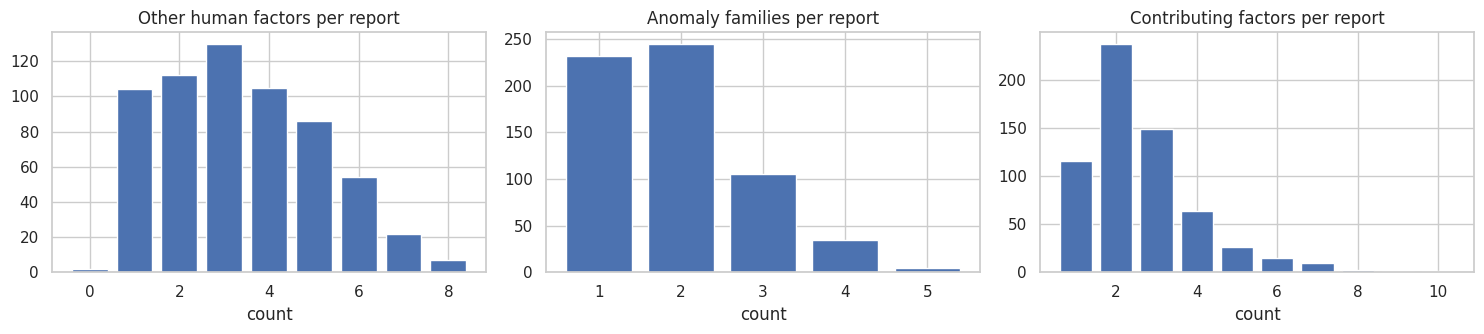

Reports where fatigue is the ONLY human factor coded: 2 (0.3%)


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col, title in zip(axes, ["n_human_factors", "n_anomaly_types", "n_contributing_factors"],
                          ["Other human factors per report", "Anomaly families per report", "Contributing factors per report"]):
    vc = df[col].value_counts().sort_index()
    ax.bar(vc.index.astype(int), vc.values, color="#4C72B0")
    ax.set_title(title)
    ax.set_xlabel("count")
save("eda_08_label_counts.png")
print("Reports where fatigue is the ONLY human factor coded:", (df["n_human_factors"] == 0).sum(),
      f"({(df['n_human_factors'] == 0).mean():.1%})")

**What co-occurs with fatigue:**
- **Fatigue rarely appears alone.** Only **256 reports (11.7%)** code fatigue as the *only* human factor. The median report has fatigue plus two other factors.
- **Situational awareness** is the most common companion (over half of reports), followed by **communication breakdown, distraction, workload, confusion and time pressure** (each roughly 24–34%). This is consistent with fatigue affecting attention and information processing.
- **Procedural deviations** (not following published procedures or clearances) are by far the most common event type, followed by **altitude deviations** and **ATC issues**. Fatigue-related reports more often describe *errors of omission or execution* than equipment failures.
- **Company policy** and **procedure** are frequent contributing factors after human factors, which hints at scheduling and organizational themes worth checking in the narratives.

## 6. Numeric Feature Distributions and Outliers

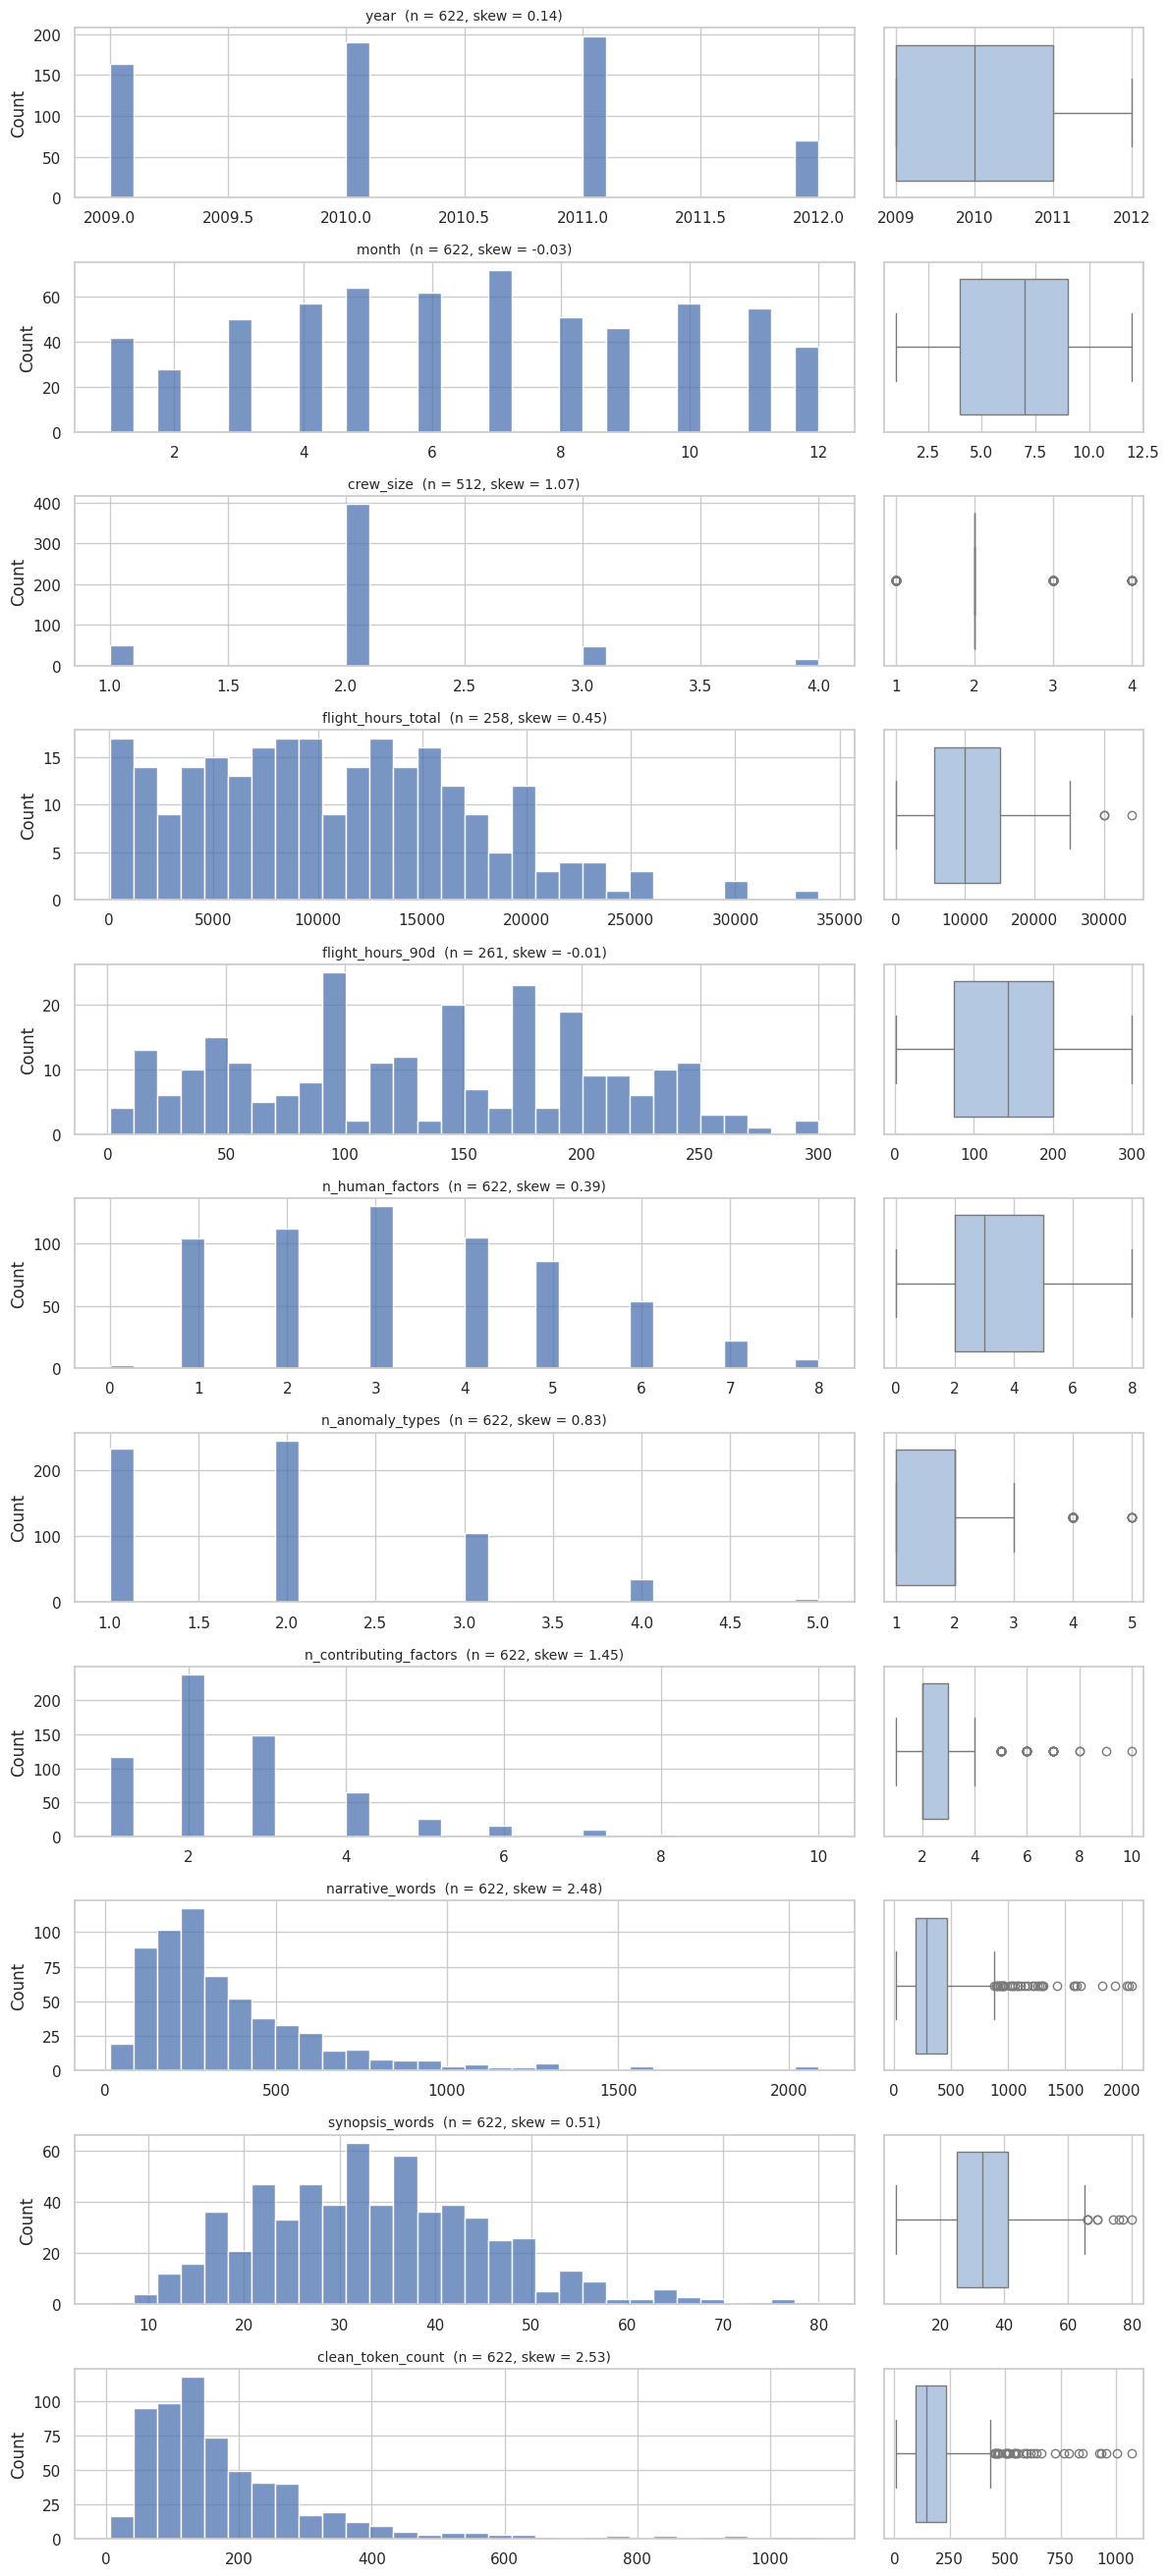

In [12]:
plot_numeric = ["year", "month", "crew_size", "flight_hours_total", "flight_hours_90d",
                "n_human_factors", "n_anomaly_types", "n_contributing_factors",
                "narrative_words", "synopsis_words", "clean_token_count"]
fig, axes = plt.subplots(len(plot_numeric), 2, figsize=(12, 2.4 * len(plot_numeric)),
                         gridspec_kw={"width_ratios": [3, 1]})
for i, col in enumerate(plot_numeric):
    data = df[col].dropna()
    sns.histplot(data, ax=axes[i, 0], bins=30, color="#4C72B0")
    axes[i, 0].set_title(f"{col}  (n = {len(data)}, skew = {data.skew():.2f})", fontsize=10)
    axes[i, 0].set_xlabel("")
    sns.boxplot(x=data, ax=axes[i, 1], color="#AEC7E8")
    axes[i, 1].set_xlabel("")
save("eda_09_numeric_distributions.png")

In [13]:
def iqr_summary(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return pd.Series({"skew": round(s.skew(), 2),
                      "IQR outliers": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
                      "% outliers": round(100 * ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean(), 1)})
display(pd.DataFrame({c: iqr_summary(df[c]) for c in plot_numeric}).T)

,skew,IQR outliers,% outliers
year,0.14,0.0,0.0
month,-0.03,0.0,0.0
crew_size,1.07,116.0,22.7
flight_hours_total,0.45,3.0,1.2
flight_hours_90d,-0.01,0.0,0.0
n_human_factors,0.39,0.0,0.0
n_anomaly_types,0.83,40.0,6.4
n_contributing_factors,1.45,55.0,8.8
narrative_words,2.48,37.0,5.9
synopsis_words,0.51,9.0,1.4


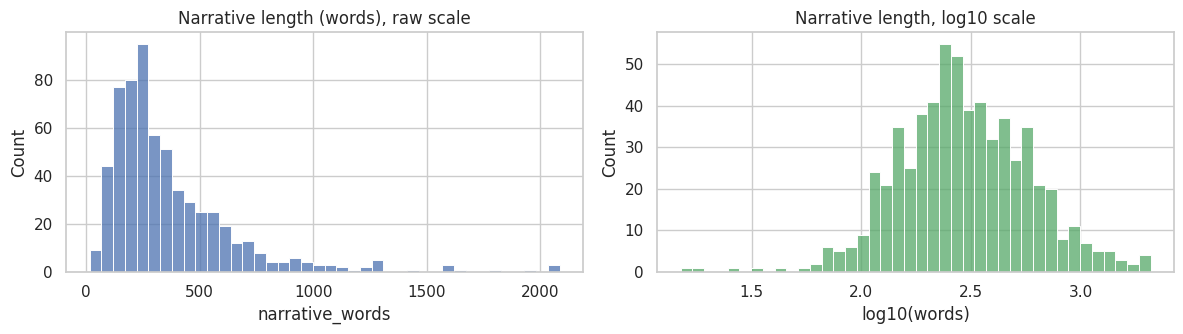

Skew raw: 2.48 | skew log10: -0.1


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(df["narrative_words"], bins=40, ax=axes[0], color="#4C72B0")
axes[0].set_title("Narrative length (words), raw scale")
sns.histplot(np.log10(df["narrative_words"]), bins=40, ax=axes[1], color="#55A868")
axes[1].set_title("Narrative length, log10 scale")
axes[1].set_xlabel("log10(words)")
save("eda_10_narrative_length_log.png")
print("Skew raw:", round(df["narrative_words"].skew(), 2), "| skew log10:", round(np.log10(df["narrative_words"]).skew(), 2))

**What the numeric distributions show:**
- **Narrative length** is strongly **right-skewed** (skew 2.21): the middle half of narratives are 200–490 words, with a long tail past 2,000. On a log scale the skew drops to −0.11, nearly symmetric. As decided in wrangling, long narratives are real and kept. TF-IDF normalization in modeling will stop them from dominating the topics.
- **Total flight hours** is moderately right-skewed (skew 0.67; a few 30,000+ hour captains). **90-day hours**, after removing implausible values in wrangling, is nearly symmetric (max 323) with no IQR outliers.
- **Contributing factors per report** has 144 IQR "outliers," but these are just reports with 5–10 contributing factors coded, which is a valid count.
- **Crew size** is almost always 2, so it carries little information.
- **Counts of human factors, anomalies and contributing factors** are small integers with mild right skew. No unusual values.
- **Year and month** have no outliers by definition.

**Outlier decision (confirming wrangling):** no further removal. The remaining extreme values are real, and the methods planned for modeling (TF-IDF, rank-based tests) are robust to them.

## 7. Relationships Between Categorical Features

### 7.1 Chi-square test and Cramér's V
For two categorical variables, a **chi-square test of independence** checks *whether* they're related, and **Cramér's V** measures *how strongly* (0 = no association, 1 = perfect association). I use Cramér's V instead of Pearson correlation because Pearson needs numbers, and these variables are categories.

Rough guide for Cramér's V: **< 0.1 negligible, 0.1–0.3 weak, 0.3–0.5 moderate, > 0.5 strong.**

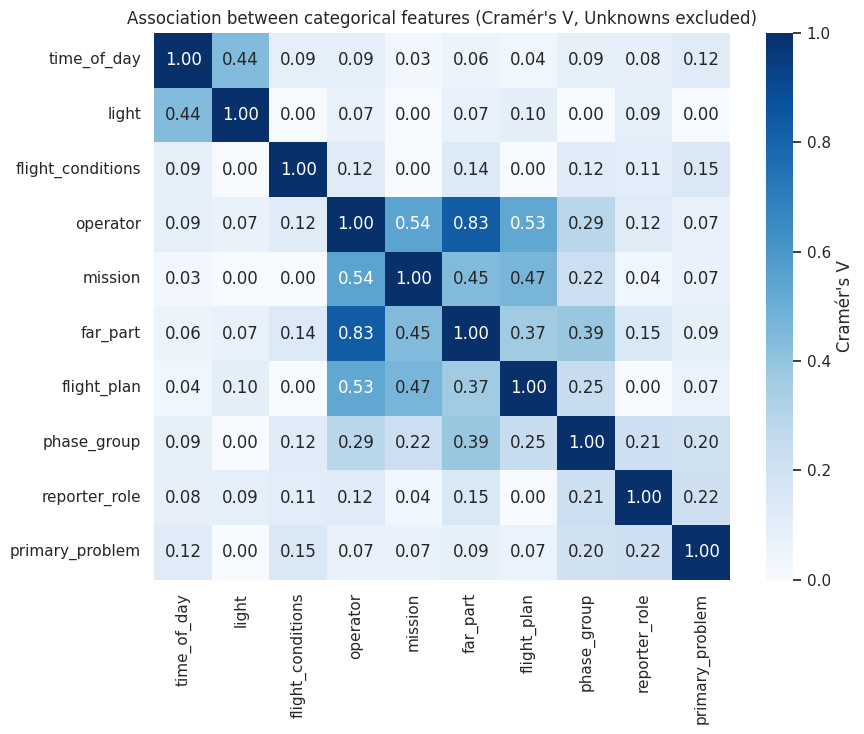

In [15]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2_stat, p, dof, _ = stats.chi2_contingency(table)
    n = table.values.sum()
    r, k = table.shape
    # bias-corrected Cramér's V (Bergsma 2013)
    phi2 = max(0, chi2_stat / n - (k - 1) * (r - 1) / (n - 1))
    r_c, k_c = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    v = np.sqrt(phi2 / max(1e-12, min(k_c - 1, r_c - 1)))
    return v, chi2_stat, p, dof

def known(*cols):
    mask = np.ones(len(df), dtype=bool)
    for c in cols:
        mask &= (df[c] != "Unknown").values
    return df[mask]

cv_matrix = pd.DataFrame(np.eye(len(CATEGORICAL)), index=CATEGORICAL, columns=CATEGORICAL)
for a, b in combinations(CATEGORICAL, 2):
    sub = known(a, b)
    v = cramers_v(sub[a], sub[b])[0]
    cv_matrix.loc[a, b] = cv_matrix.loc[b, a] = v

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(cv_matrix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "Cramér's V"})
ax.set_title("Association between categorical features (Cramér's V, Unknowns excluded)")
save("eda_11_cramers_v_heatmap.png")

In [16]:
pairs = (cv_matrix.where(np.triu(np.ones(cv_matrix.shape), k=1).astype(bool))
         .stack().rename("cramers_v").sort_values(ascending=False).reset_index())
pairs.columns = ["feature_1", "feature_2", "cramers_v"]
display(pairs.head(10).round(2))

,feature_1,feature_2,cramers_v
0,operator,far_part,0.83
1,operator,mission,0.54
2,operator,flight_plan,0.53
3,mission,flight_plan,0.47
4,mission,far_part,0.45
5,time_of_day,light,0.44
6,far_part,phase_group,0.39
7,far_part,flight_plan,0.37
8,operator,phase_group,0.29
9,flight_plan,phase_group,0.25


**Collinearity among categorical features.** The strongest associations are among the **operation-type variables**: **operator–FAR Part (V = 0.81, strong)**, mission–FAR Part (0.58) and operator–mission (0.57). That's expected because they describe overlapping things: Air Carrier operators almost always fly under Part 121, usually carrying passengers. **Time of day and light** are moderately linked (V = 0.44), which makes sense since night happens at night. FAR Part is also moderately associated with reporter role (0.48), because controllers, technicians and flight attendants mostly appear in Part 121 reports.

**Decision:** these groups are partly **redundant**. Using all four operation-type variables to compare narrative themes would repeat the same comparison four times. I'll keep **`operator`** (clearest categories, fewest Unknowns) and **`mission`** (the dimension named in the research question), and treat **FAR Part** and **flight plan** as redundant. Similarly, I'll keep **`time_of_day`** (more complete) over **`light`**.

### 7.2 Flight phase × time of day

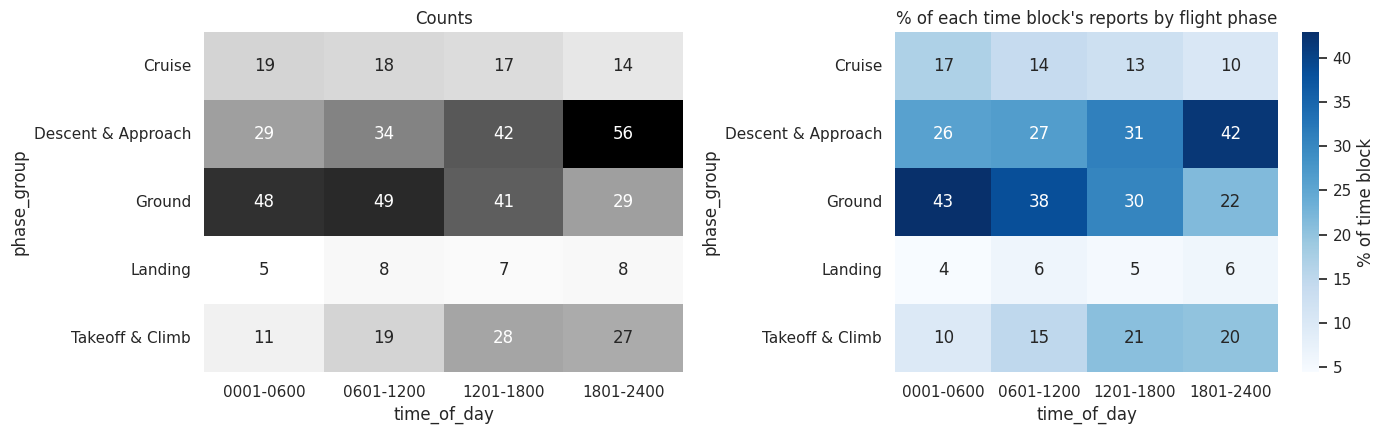

Chi-square = 24.7, dof = 12, p = 1.62e-02, Cramér's V = 0.09
Smallest expected cell count: 6.2 (chi-square needs >= 5)


In [17]:
sub = known("phase_group", "time_of_day")
sub = sub[sub["phase_group"] != "Other"]
ct = pd.crosstab(sub["phase_group"], sub["time_of_day"])
ct_pct = pd.crosstab(sub["phase_group"], sub["time_of_day"], normalize="columns") * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(ct, annot=True, fmt="d", cmap="Greys", ax=axes[0], cbar=False)
axes[0].set_title("Counts")
sns.heatmap(ct_pct, annot=True, fmt=".0f", cmap="Blues", ax=axes[1], cbar_kws={"label": "% of time block"})
axes[1].set_title("% of each time block's reports by flight phase")
save("eda_12_phase_by_time.png")

v, chi2_stat, p, dof = cramers_v(sub["phase_group"], sub["time_of_day"])
print(f"Chi-square = {chi2_stat:.1f}, dof = {dof}, p = {p:.2e}, Cramér's V = {v:.2f}")
expected = stats.chi2_contingency(ct)[3]
print("Smallest expected cell count:", round(expected.min(), 1), "(chi-square needs >= 5)")

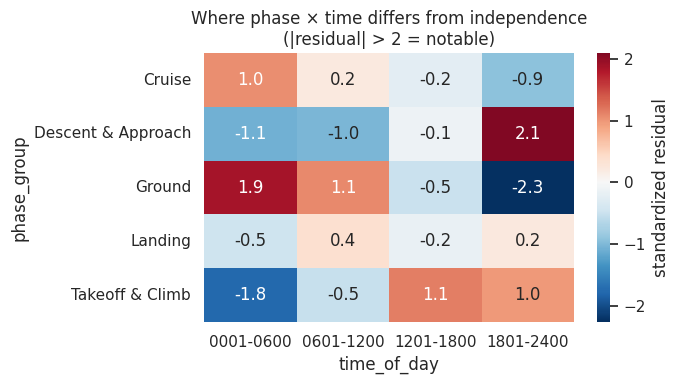

In [18]:
residuals = (ct - expected) / np.sqrt(expected)
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(residuals, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "standardized residual"})
ax.set_title("Where phase × time differs from independence\n(|residual| > 2 = notable)")
save("eda_13_phase_time_residuals.png")

**Hypothesis test.**
- **H₀:** the flight phase in fatigue reports is independent of time of day.
- **H₁:** the mix of flight phases differs by time of day.

**Result:** the chi-square test rejects independence (χ² = 32.4, df = 12, p = 0.001), and every expected cell count is well above 5 (smallest 25.7), so the test is valid. **But the effect is negligible (Cramér's V = 0.06).** This is a good example of why effect size matters: with 2,000 reports, even a tiny difference becomes "significant."

The **standardized residuals** show where the small difference is. The one clear cell is **Ground in the late-night block (+3.3)**: 37% of overnight reports happen while parked or taxiing, compared with 24–28% at other times. Takeoff & Climb is under-represented overnight (−2.0). A likely explanation is **overnight maintenance work and early-morning pre-departure activity** happening on the ground, which the reporter-role analysis below supports.

**Decision:** because flight phase and time of day are only weakly associated, they carry **different information** and both can be kept as separate lenses for comparing narrative themes. This is an association within the reports, not evidence that a phase is riskier at a given hour.

### 7.3 Reporter role × co-occurring human factors

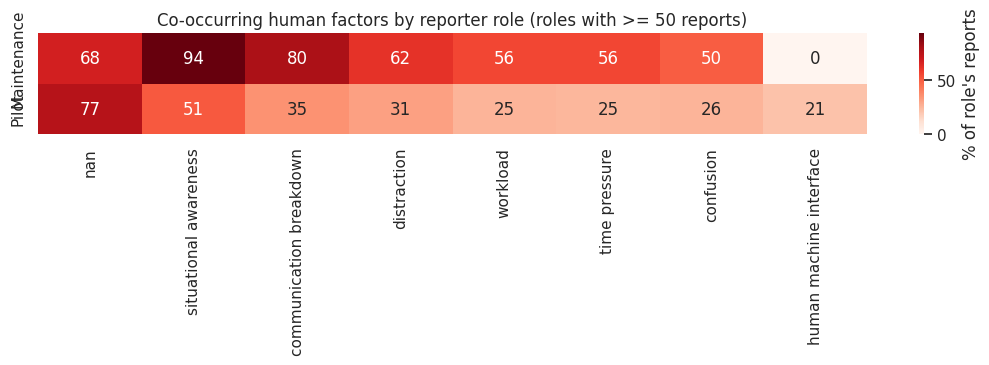

,human factor,chi2,p-value,Cramér's V,significant after Bonferroni
2,hf_communication_breakdown,36.2,1.812549e-09,0.25,True
1,hf_situational_awareness,32.0,1.580410e-08,0.23,True
5,hf_time_pressure,20.8,5.169328e-06,0.19,True
4,hf_workload,19.7,8.832678e-06,0.18,True
3,hf_distraction,17.8,2.514860e-05,0.17,True
6,hf_confusion,12.4,4.208279e-04,0.14,True
7,hf_human_machine_interface,12.0,5.265271e-04,0.14,True
0,hf_nan,1.6,2.112436e-01,0.03,False


In [19]:
roles = df["reporter_role"].value_counts()
main_roles = roles[roles >= MIN_GROUP].index.drop("Unknown", errors="ignore")
hf_cols = list(hf_prev.index[:8])
hf_cols = ["hf_" + c.replace(" ", "_") for c in hf_cols]
role_hf = df[df["reporter_role"].isin(main_roles)].groupby("reporter_role")[hf_cols].mean() * 100
role_hf.columns = [c.replace("hf_", "").replace("_", " ") for c in role_hf.columns]

fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(role_hf, annot=True, fmt=".0f", cmap="Reds", ax=ax, cbar_kws={"label": "% of role's reports"})
ax.set_title("Co-occurring human factors by reporter role (roles with >= 50 reports)")
ax.set_ylabel("")
save("eda_14_role_by_hf.png")

role_tests = []
sub = df[df["reporter_role"].isin(main_roles)]
for col in hf_cols:
    v, chi2_stat, p, dof = cramers_v(sub["reporter_role"], sub[col])
    role_tests.append({"human factor": col, "chi2": round(chi2_stat, 1), "p-value": p, "Cramér's V": round(v, 2)})
role_tests = pd.DataFrame(role_tests).sort_values("Cramér's V", ascending=False)
role_tests["significant after Bonferroni"] = role_tests["p-value"] < 0.05 / len(role_tests)
display(role_tests)

**What this shows.** Running eight tests at once raises the chance of a false positive, so I use a **Bonferroni correction**: each test must reach p < 0.05 / 8 ≈ 0.006 to count as significant. **All eight human factors differ significantly by role**, though the effects are weak to modest (Cramér's V 0.09–0.21). The largest difference is **workload** (V = 0.21).

Reading across the heat map:
- **Air traffic controllers** report the highest rates of **situational awareness (71%)** and **workload (61%)** problems alongside fatigue, which fits controlling busy traffic while tired.
- **Maintenance technicians** stand out for **communication breakdown (58%)**, **time pressure (49%)** and **workload (49%)**, consistent with shift handovers and pressure to return aircraft to service.
- **Flight attendants** have the *lowest* rates of almost every co-occurring factor. Their reports focus on fatigue itself and its causes, which the vocabulary analysis in Section 9.3 confirms.
- **Pilots** sit in the middle on most factors and are highest on **human-machine interface (17%)**, which fits automation and cockpit systems.

**Implication:** reporter role is a **meaningful feature**. Topic results in Step 4 should be checked by role, so that themes that are really occupation-specific aren't presented as universal.

### 7.4 Narrative length by group (non-parametric test)

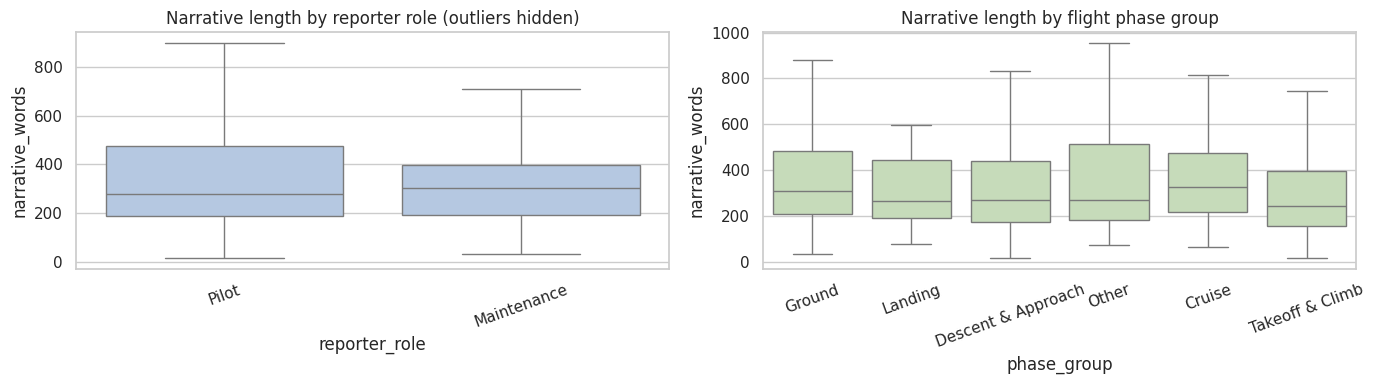

Kruskal-Wallis, length by role:  H = 0.2, p = 6.91e-01
Kruskal-Wallis, length by phase: H = 7.1, p = 2.14e-01


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sub = df[df["reporter_role"].isin(main_roles)]
sns.boxplot(data=sub, x="reporter_role", y="narrative_words", ax=axes[0], color="#AEC7E8", showfliers=False)
axes[0].set_title("Narrative length by reporter role (outliers hidden)")
axes[0].tick_params(axis="x", rotation=20)
sub2 = known("phase_group")
sns.boxplot(data=sub2, x="phase_group", y="narrative_words", ax=axes[1], color="#C5E0B4", showfliers=False)
axes[1].set_title("Narrative length by flight phase group")
axes[1].tick_params(axis="x", rotation=20)
save("eda_15_length_by_group.png")

h1, p1 = stats.kruskal(*[g["narrative_words"].values for _, g in sub.groupby("reporter_role")])
h2, p2 = stats.kruskal(*[g["narrative_words"].values for _, g in sub2.groupby("phase_group")])
print(f"Kruskal-Wallis, length by role:  H = {h1:.1f}, p = {p1:.2e}")
print(f"Kruskal-Wallis, length by phase: H = {h2:.1f}, p = {p2:.2e}")

**Why Kruskal-Wallis?** Narrative length is heavily skewed, so a test that compares means (ANOVA) isn't appropriate. Kruskal-Wallis compares groups using **ranks**, so outliers and skew don't distort it.

**Results:** narrative length **differs by reporter role** (H = 17.9, p < 0.001). Flight attendants write the shortest narratives (median ~240 words vs. ~310 for pilots and controllers). Length **does not differ by flight phase** (p = 0.90). Because length varies by role, topic models could pick up role-related length effects, which is another reason to use TF-IDF normalization.

## 8. Pearson Correlation: Numeric and Indicator Features

Pearson correlation measures the **linear** relationship between two numeric variables (−1 to +1). Between two 0/1 indicator columns, Pearson's r equals the **phi coefficient**, a standard measure of association for binary variables. So one correlation matrix can include the numeric features *and* the human-factor, anomaly and contributing-factor indicators.

I exclude `hf_fatigue` (it's nearly always 1, so it has almost no variance) and indicators present in fewer than 2% of reports (too rare for stable correlations).

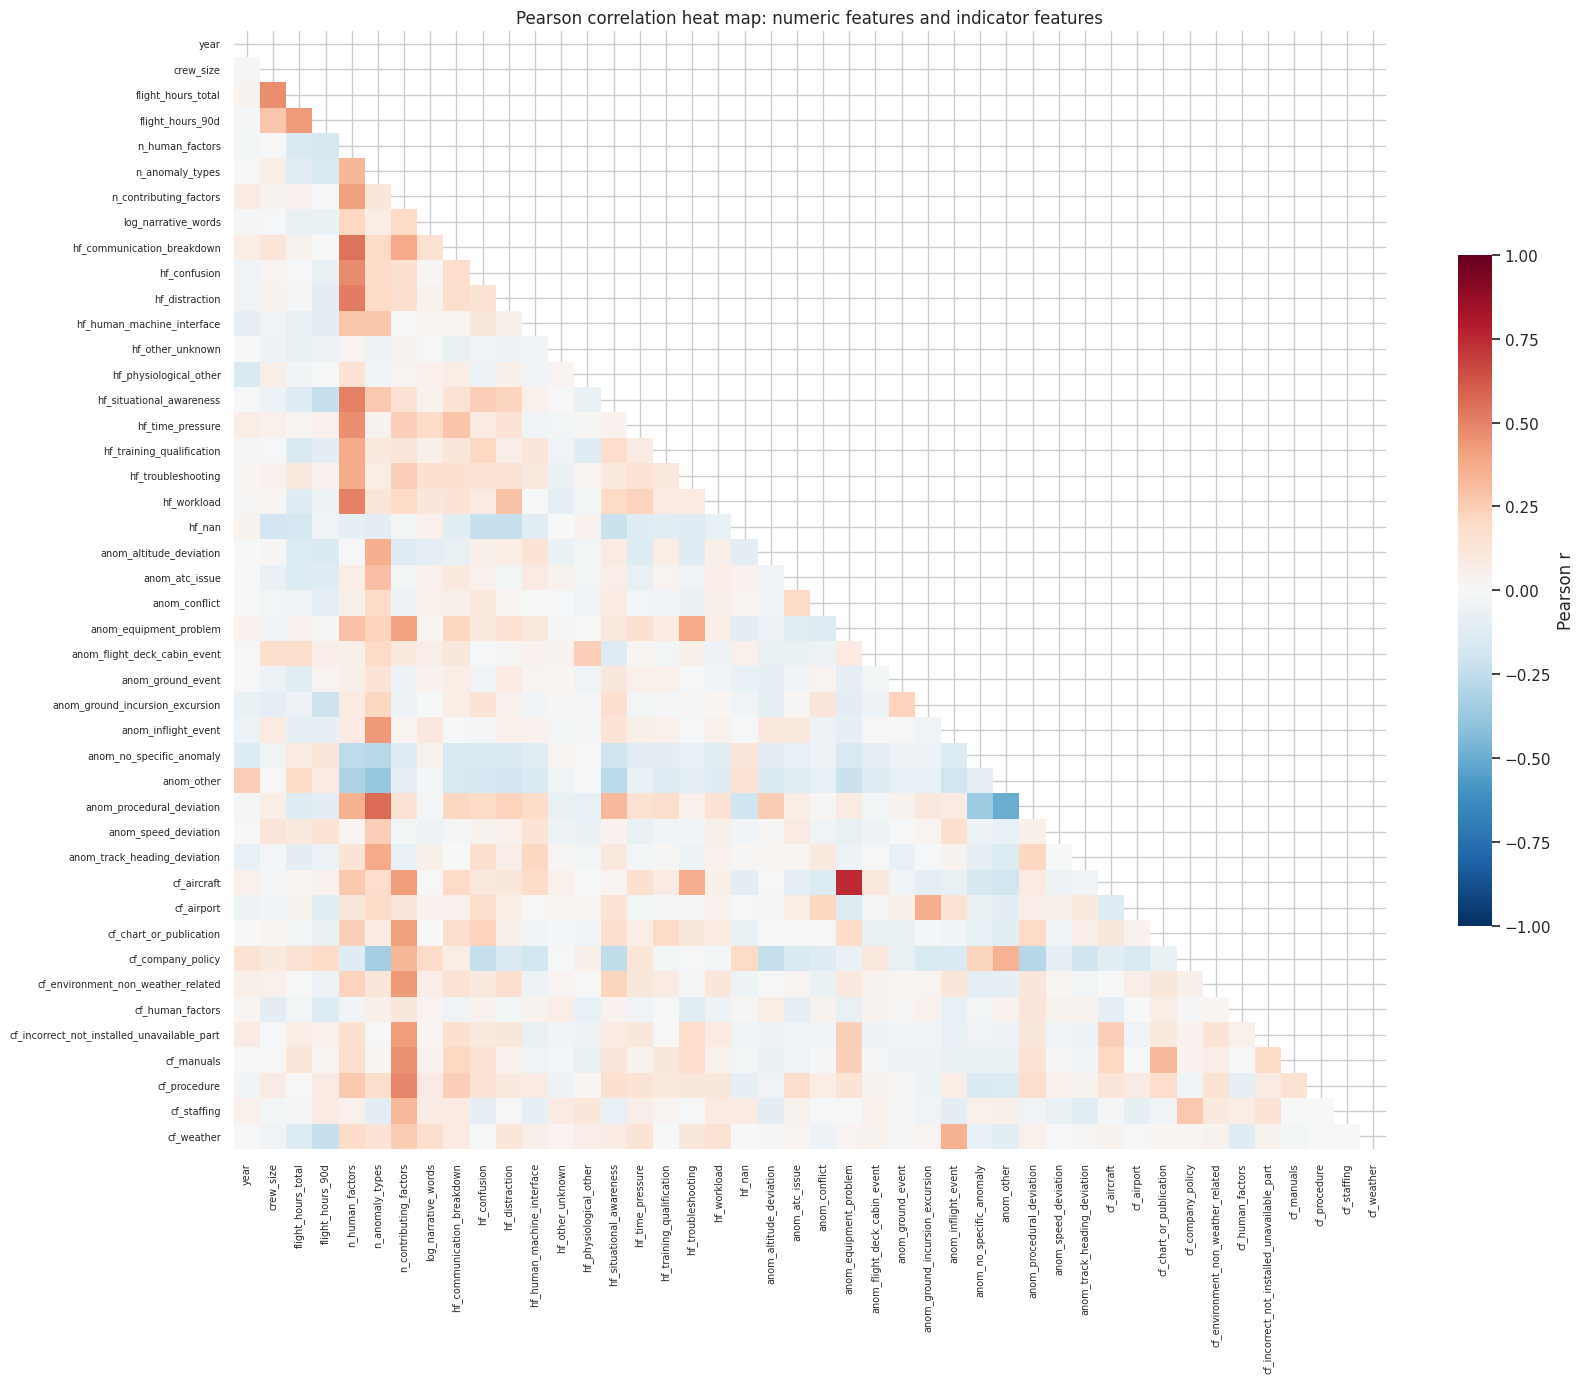

In [21]:
NUM_FOR_CORR = ["year", "crew_size", "flight_hours_total", "flight_hours_90d",
                "n_human_factors", "n_anomaly_types", "n_contributing_factors", "log_narrative_words"]
indicators = [c for c in HF + ANOM + CF if c != "hf_fatigue" and df[c].mean() >= 0.02]
corr_cols = NUM_FOR_CORR + indicators
corr = df[corr_cols].corr(method="pearson")

fig, ax = plt.subplots(figsize=(17, 14))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax,
            cbar_kws={"label": "Pearson r", "shrink": 0.6}, xticklabels=True, yticklabels=True)
ax.tick_params(labelsize=7)
ax.set_title("Pearson correlation heat map: numeric features and indicator features")
save("eda_16_pearson_heatmap.png")

In [22]:
corr_pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
              .stack().rename("r").reset_index())
corr_pairs.columns = ["feature_1", "feature_2", "r"]
corr_pairs["|r|"] = corr_pairs["r"].abs()
display(corr_pairs.sort_values("|r|", ascending=False).head(15).round(2))
print("Pairs with |r| > 0.7 (collinear):", (corr_pairs["|r|"] > 0.7).sum())

,feature_1,feature_2,r,|r|
745,anom_equipment_problem,cf_aircraft,0.75,0.75
229,n_anomaly_types,anom_procedural_deviation,0.56,0.56
169,n_human_factors,hf_communication_breakdown,0.55,0.55
171,n_human_factors,hf_distraction,0.52,0.52
175,n_human_factors,hf_situational_awareness,0.50,0.50
179,n_human_factors,hf_workload,0.50,0.50
841,anom_other,anom_procedural_deviation,-0.50,0.50
277,n_contributing_factors,cf_procedure,0.49,0.49
170,n_human_factors,hf_confusion,0.47,0.47
176,n_human_factors,hf_time_pressure,0.47,0.47


Pairs with |r| > 0.7 (collinear): 1


**What the correlation matrix shows:**
- **Count features vs. their own indicators.** `n_human_factors` correlates with the individual human-factor indicators, and `n_contributing_factors` with the contributing-factor indicators, because the counts are *built from* them. These are mechanical relationships, not findings.
- **The one collinear pair (|r| > 0.7):** the *equipment problem* anomaly and the *aircraft* contributing factor (**r = 0.74**). NASA analysts code the same event in two places: when equipment fails, "Aircraft" is listed as a contributing factor. **Decision:** keep `anom_equipment_problem` (it describes the event) and drop `cf_aircraft` from comparisons as redundant.
- Other cross-field links are moderate, e.g. *ground incursion/excursion* with the *airport* contributing factor (r = 0.40).
- **Crew size and total flight hours** (r = 0.46): larger crews are airline crews, whose captains have more hours.
- **Narrative length** has a weak positive correlation with the number of human factors (r = 0.20) and contributing factors (r = 0.17). Longer, more detailed reports give analysts more to code.
- **Pilot total flight hours** has a weak *negative* correlation with the number of co-occurring human factors (r = −0.10). More experienced pilots' reports list slightly fewer companion factors, but the relationship is very weak.

### 8.1 Spearman check for the numeric features
Pearson only captures straight-line relationships and is sensitive to skew. As a check, I compare it with **Spearman's rank correlation** for the numeric features.

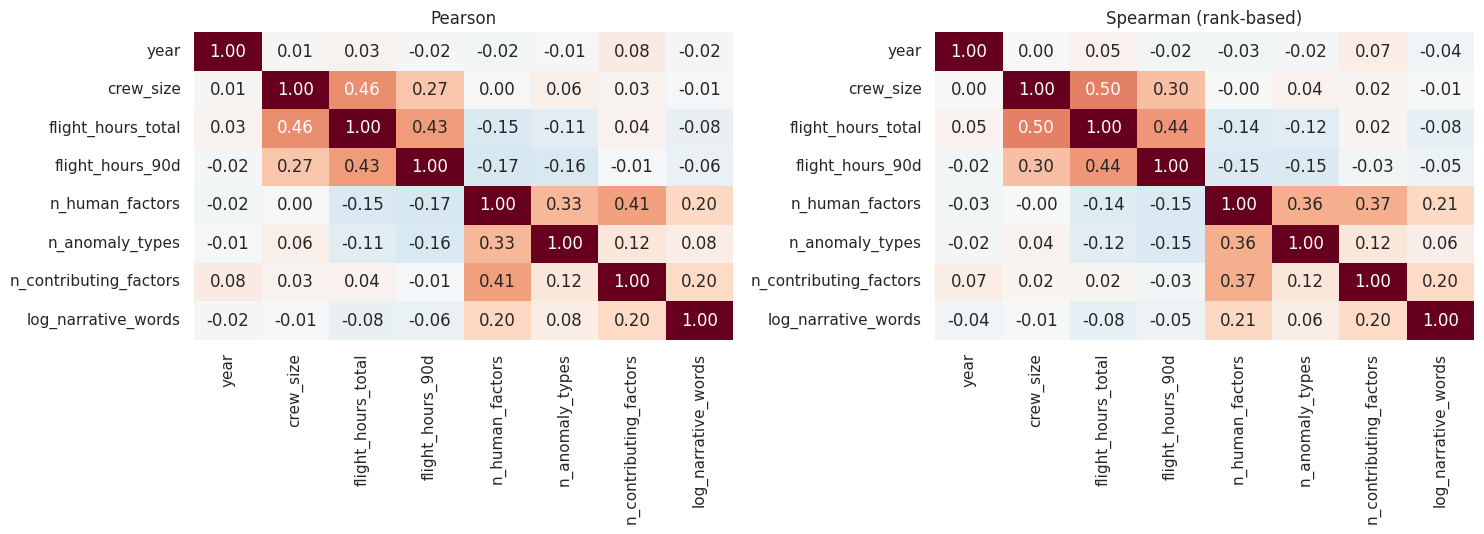

In [23]:
num_only = df[NUM_FOR_CORR]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(num_only.corr("pearson"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title("Pearson")
sns.heatmap(num_only.corr("spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[1], cbar=False)
axes[1].set_title("Spearman (rank-based)")
save("eda_17_pearson_vs_spearman.png")

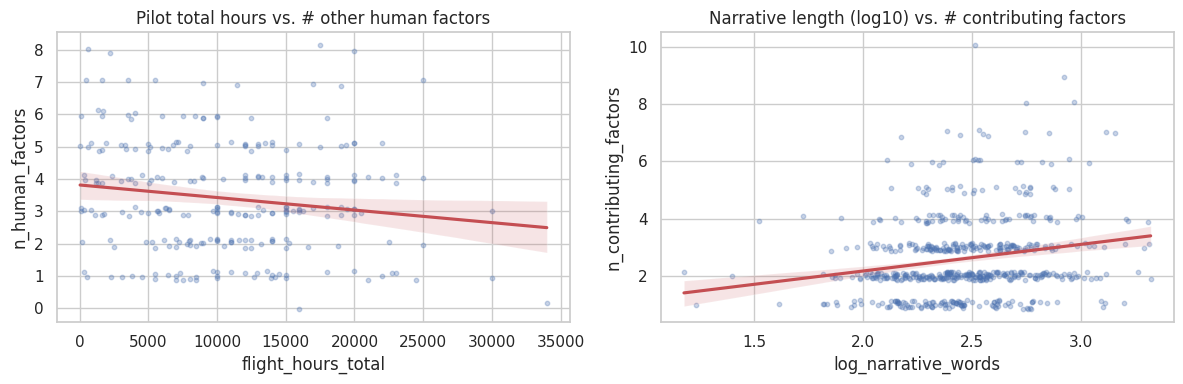

    flight_hours_total vs n_human_factors          Pearson r = -0.15 (p = 0.0161, n = 258)
   log_narrative_words vs n_contributing_factors   Pearson r = +0.20 (p = 3.55e-07, n = 622)
   log_narrative_words vs n_human_factors          Pearson r = +0.20 (p = 2.9e-07, n = 622)
                  year vs log_narrative_words      Pearson r = -0.02 (p = 0.665, n = 622)


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.regplot(data=df, x="flight_hours_total", y="n_human_factors", ax=axes[0],
            scatter_kws={"alpha": 0.3, "s": 10}, line_kws={"color": "#C44E52"}, x_jitter=0, y_jitter=0.15)
axes[0].set_title("Pilot total hours vs. # other human factors")
sns.regplot(data=df, x="log_narrative_words", y="n_contributing_factors", ax=axes[1],
            scatter_kws={"alpha": 0.3, "s": 10}, line_kws={"color": "#C44E52"}, y_jitter=0.15)
axes[1].set_title("Narrative length (log10) vs. # contributing factors")
save("eda_18_scatter_biplots.png")

for x, y in [("flight_hours_total", "n_human_factors"), ("log_narrative_words", "n_contributing_factors"),
             ("log_narrative_words", "n_human_factors"), ("year", "log_narrative_words")]:
    pair = df[[x, y]].dropna()
    r, p = stats.pearsonr(pair[x], pair[y])
    print(f"{x:>22} vs {y:<24} Pearson r = {r:+.2f} (p = {p:.3g}, n = {len(pair)})")

**Interpretation.** Pearson and Spearman agree closely, so the relationships aren't artifacts of skew. Apart from the expected links (crew size with hours, total hours with 90-day hours, and the count features with each other), correlations among the numeric features are **weak (|r| < 0.3)**. Report year is unrelated to narrative length (r = 0.03). With 2,000+ reports, even tiny correlations can be "statistically significant" (r = −0.10 has p = 0.01), so I focus on **effect size (r)** rather than p-values alone.

## 9. Text EDA: What Do the Narratives Say?

### 9.1 Word counts before and after cleaning

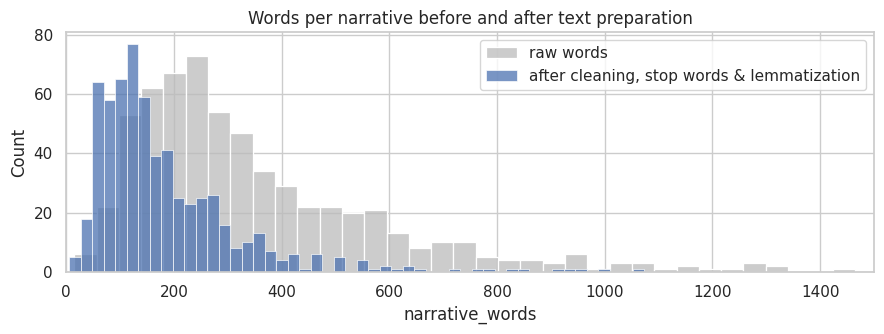

Median raw words: 279.5 | median cleaned tokens: 143.5
Share of words removed by cleaning: 0.504


In [25]:
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.histplot(df["narrative_words"], bins=50, color="#BBBBBB", label="raw words", ax=ax)
sns.histplot(df["clean_token_count"], bins=50, color="#4C72B0", label="after cleaning, stop words & lemmatization", ax=ax)
ax.set_xlim(0, 1500)
ax.legend()
ax.set_title("Words per narrative before and after text preparation")
save("eda_19_wordcount_before_after.png")
print("Median raw words:", df["narrative_words"].median(), "| median cleaned tokens:", df["clean_token_count"].median())
print("Share of words removed by cleaning:", round(1 - df["clean_token_count"].sum() / df["narrative_words"].sum(), 3))

### 9.2 Most frequent unigrams, bigrams and trigrams

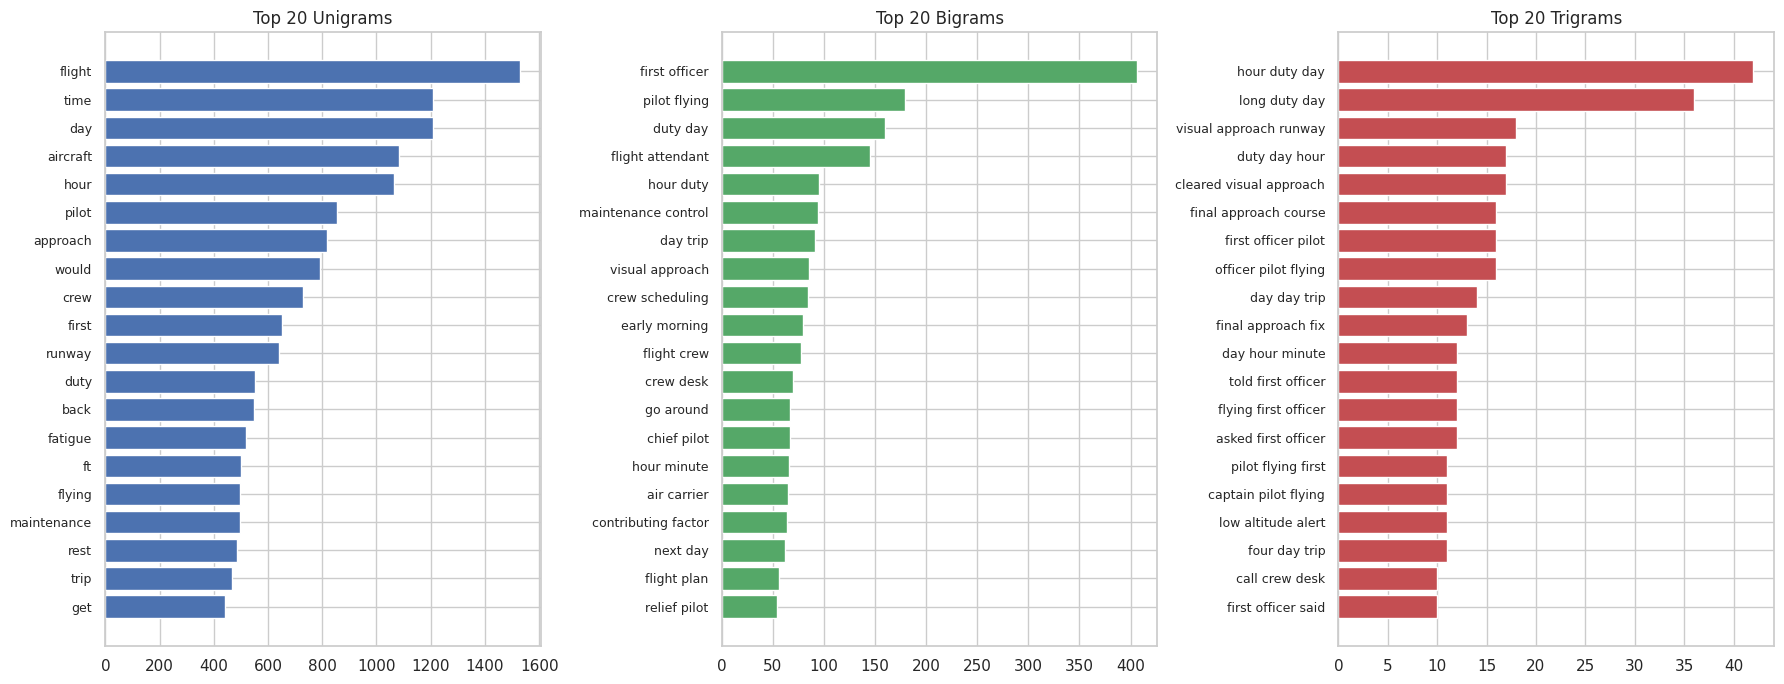

In [26]:
def top_ngrams(texts, n, k=20, min_df=5):
    vec = CountVectorizer(ngram_range=(n, n), min_df=min_df)
    X = vec.fit_transform(texts)
    freq = np.asarray(X.sum(axis=0)).ravel()
    docfreq = np.asarray((X > 0).sum(axis=0)).ravel()
    out = pd.DataFrame({"ngram": vec.get_feature_names_out(), "count": freq,
                        "% of narratives": np.round(100 * docfreq / X.shape[0], 1)})
    return out.sort_values("count", ascending=False).head(k)

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
ngram_tables = {}
for ax, n, title, color in zip(axes, [1, 2, 3], ["Unigrams", "Bigrams", "Trigrams"], ["#4C72B0", "#55A868", "#C44E52"]):
    t = top_ngrams(df["text_lemma"], n)
    ngram_tables[n] = t
    ax.barh(t["ngram"][::-1], t["count"][::-1], color=color)
    ax.set_title(f"Top 20 {title}")
    ax.tick_params(axis="y", labelsize=9)
save("eda_20_top_ngrams.png")

**What the n-grams show.**
- **Unigrams** are dominated by general words (*flight, aircraft, time, day, hour, would, us*). They appear in so many narratives that they can't tell one theme from another.
- **Bigrams and trigrams are much more informative.** Phrases such as *duty day*, *hour duty day*, *long duty day*, *long day*, *day trip*, *crew scheduling* and *early morning* point to a **scheduling and duty-time** theme. *Visual approach*, *final approach*, *glide slope*, *go around* and *low altitude alert* point to an **approach and landing** theme. *First officer*, *pilot flying*, *pilot monitoring* and *flight attendant* point to **crew roles and coordination**, and *maintenance control* to **maintenance operations**.
- Some frequent phrases are reporting filler (*gave us*, *cleared us*, *make sure*). They'll be handled with a small custom stop word list.
- **Decision for modeling:** include **bigrams** in the vectorizer (`ngram_range=(1, 2)`). They carry much of the meaning in aviation language (e.g., *first officer* vs. *officer*). Trigrams add little beyond bigrams and greatly increase vocabulary size, so I'll leave them out.

### 9.3 How often do narratives use fatigue vocabulary?
This uses the **original** narrative text (before stop word removal) so phrases like *"red eye"* and *"back side of the clock"* are preserved.

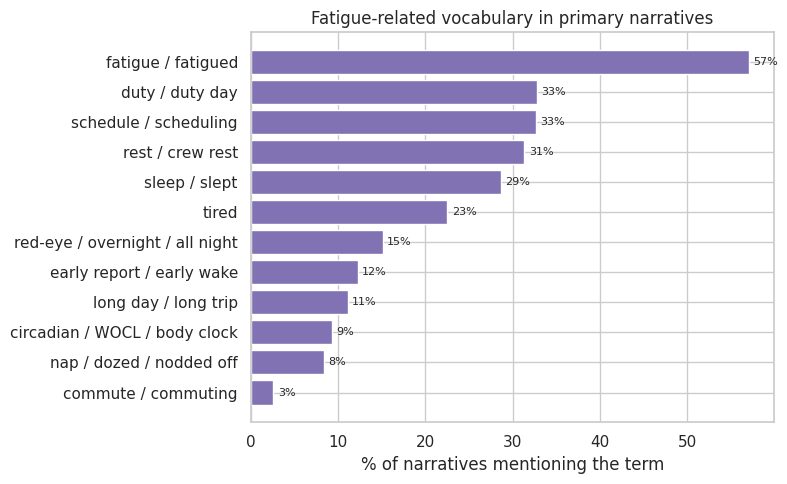

In [27]:
FATIGUE_TERMS = {
    "fatigue / fatigued": r"\bfatigu",
    "tired": r"\btired",
    "sleep / slept": r"\bsleep|\bslept",
    "rest / crew rest": r"\brest\b|\brested\b|crew rest",
    "duty / duty day": r"\bduty\b",
    "long day / long trip": r"\blong (?:day|trip|night|duty)",
    "circadian / WOCL / body clock": r"circadian|\bwocl\b|body clock|back side of the clock",
    "red-eye / overnight / all night": r"red[ -]?eye|\bovernight\b|all night",
    "early report / early wake": r"early (?:report|show|wake|morning)|\b0[3-5]\d\d\b",
    "nap / dozed / nodded off": r"\bnap\b|\bnapp|doz(?:e|ed|ing)|nodd?ed off|fell asleep",
    "schedule / scheduling": r"\bschedul",
    "commute / commuting": r"\bcommut",
}
lower = df["narrative_1"].str.lower()
term_prev = pd.Series({k: lower.str.contains(v, regex=True).mean() * 100 for k, v in FATIGUE_TERMS.items()}).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(term_prev.index, term_prev.values, color="#8172B3")
for i, v in enumerate(term_prev.values):
    ax.text(v + 0.5, i, f"{v:.0f}%", va="center", fontsize=8)
ax.set_xlabel("% of narratives mentioning the term")
ax.set_title("Fatigue-related vocabulary in primary narratives")
save("eda_21_fatigue_vocabulary.png")

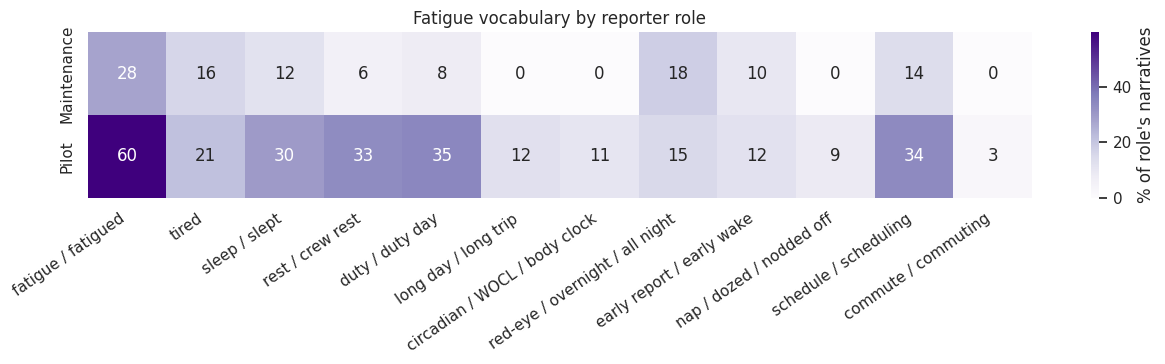

In [28]:
term_by_role = pd.DataFrame({k: df.loc[df["reporter_role"].isin(main_roles)].assign(m=lower.str.contains(v, regex=True))
                                 .groupby("reporter_role")["m"].mean() * 100
                             for k, v in FATIGUE_TERMS.items()})
fig, ax = plt.subplots(figsize=(13, 3.8))
sns.heatmap(term_by_role, annot=True, fmt=".0f", cmap="Purples", ax=ax, cbar_kws={"label": "% of role's narratives"})
ax.set_title("Fatigue vocabulary by reporter role")
ax.set_ylabel("")
plt.xticks(rotation=35, ha="right")
save("eda_22_fatigue_vocab_by_role.png")

**What the fatigue vocabulary shows.**
- About half of narratives (**54%**) name *fatigue* directly, and about a quarter say *tired* (23%). Just as often, narratives describe **fatigue's causes and context**: *rest* (27%), *schedule* (27%), *duty* (27%) and *sleep* (25%), plus red-eye or overnight flying (12%). This supports the plan to look for themes about **scheduling, duty and rest** alongside themes about **operational events**.
- **Flight attendants describe fatigue through their work rules:** 47% mention *schedules*, 43% *rest*, and 43% *duty*, far more than pilots (28–29%) or controllers (7–14%). Controllers and technicians mention duty and rest least. Each occupation frames fatigue in terms of its own working conditions.
- About **3 in 10 primary narratives contain no explicit fatigue word** (fatigue, tired, exhausted, sleep, drowsy) even though fatigue is coded. The fatigue may be implied, described in the second narrative, or inferred by NASA analysts. This is a known limitation: **text-based fatigue detection and analyst coding don't fully overlap.**

### 9.4 Which words are distinctive for each flight phase?
Section 7 showed flight phase is a well-balanced grouping. Here I use a **chi-square feature-selection test** (`sklearn.feature_selection.chi2`) to find the words most *strongly associated* with each phase group compared with all other phases. This previews whether the text carries phase-specific information, which would support comparing topics by phase in Step 4.

In [29]:
phase_df = df[~df["phase_group"].isin(["Unknown", "Other"])]
vec = CountVectorizer(ngram_range=(1, 2), min_df=10, max_df=0.5)
X_phase = vec.fit_transform(phase_df["text_lemma"])
terms = vec.get_feature_names_out()

distinct = {}
for phase in sorted(phase_df["phase_group"].unique()):
    y = (phase_df["phase_group"] == phase).astype(int)
    scores, _ = chi2(X_phase, y)
    in_group = np.asarray(X_phase[y.values == 1].mean(axis=0)).ravel()
    out_group = np.asarray(X_phase[y.values == 0].mean(axis=0)).ravel()
    over = in_group > out_group                     # keep words OVER-used in this phase
    order = np.argsort(-np.where(over, scores, 0))[:12]
    distinct[phase] = terms[order]
distinct_df = pd.DataFrame(distinct)
display(distinct_df)

,Cruise,Descent & Approach,Ground,Landing,Takeoff & Climb
0,destination,approach,maintenance,runway,takeoff
1,center,ft,crew,landing,departure
2,fl,visual,card,wind,climb
3,emergency,il,mechanic,centerline,sid
4,cruise,altitude,taxiway,foot,bleed
5,fuel,descent,gate,gear,checklist
6,plan,visual approach,ramp,tower,climbing
7,enroute,localizer,duty,airspeed,routing
8,burn,glide,hotel,fast,initial
9,direct,final,part,approach,takeoff clearance


**What this shows.** Each phase group has clearly distinct vocabulary:
- **Ground:** *maintenance, mechanic, ramp, gate, taxiway, door, parking*, and also *scheduling* and *hour*. Ground reports combine maintenance work with duty-time and scheduling concerns.
- **Takeoff & Climb:** *takeoff checklist, takeoff clearance, departure, SID, PDC (pre-departure clearance)*.
- **Cruise:** *break, bunk, rest, sector, fuel*. In-flight **rest breaks and crew bunks** are distinctive to cruise, a fatigue-specific theme.
- **Descent & Approach:** *approach, descent, visual, ILS, glide slope, localizer, altitude, speed*.
- **Landing:** *flare, touched, braking, skid, go around, tower*.

The **text carries information that lines up with the structured fields**, which supports Stage 4 of the project plan (comparing narrative themes with structured characteristics). The cruise rest-and-bunk vocabulary is a good sign that topic modeling can separate fatigue *management* themes from operational *event* themes.

### 9.5 Choosing vectorizer settings: document frequency and domain stop words
Topic models work best when the vocabulary excludes (a) **very rare words**, which are typos, unique place names and one-off details, and (b) **words that appear in almost every document**, which can't distinguish topics. I look at *document frequency*, the share of narratives each word appears in, to choose the cut-offs from the data.

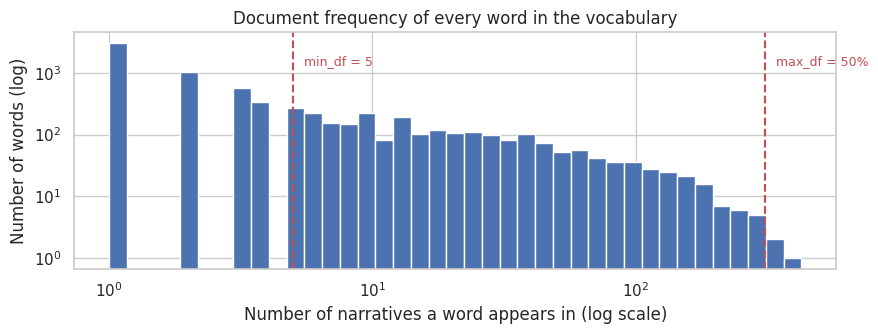

,setting,vocabulary size
0,all words,7472
1,appear in >= 5 narratives,2429
2,appear in >= 5 and <= 50% of narratives,2424


Words appearing in only 1 narrative: 3068 (41% of vocabulary)


In [30]:
vec_all = CountVectorizer(min_df=1)
X_all = vec_all.fit_transform(df["text_lemma"])
doc_freq = pd.Series(np.asarray((X_all > 0).sum(axis=0)).ravel(), index=vec_all.get_feature_names_out())

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(doc_freq, bins=np.logspace(0, np.log10(doc_freq.max()), 40), color="#4C72B0")
ax.set_xscale("log")
ax.set_yscale("log")
for x, lbl in [(5, "min_df = 5"), (0.5 * len(df), "max_df = 50%")]:
    ax.axvline(x, color="#C44E52", ls="--")
    ax.text(x * 1.1, ax.get_ylim()[1] * 0.3, lbl, color="#C44E52", fontsize=9)
ax.set_xlabel("Number of narratives a word appears in (log scale)")
ax.set_ylabel("Number of words (log)")
ax.set_title("Document frequency of every word in the vocabulary")
save("eda_23_document_frequency.png")

vocab_table = pd.DataFrame({
    "setting": ["all words", "appear in >= 5 narratives", "appear in >= 5 and <= 50% of narratives"],
    "vocabulary size": [len(doc_freq), (doc_freq >= 5).sum(), ((doc_freq >= 5) & (doc_freq <= 0.5 * len(df))).sum()],
})
display(vocab_table)
print("Words appearing in only 1 narrative:", (doc_freq == 1).sum(), f"({(doc_freq == 1).mean():.0%} of vocabulary)")

In [31]:
very_common = (doc_freq / len(df)).sort_values(ascending=False).head(25).round(2)
display(very_common.rename("share of narratives").to_frame().T)

,time,flight,day,hour,aircraft,would,first,fatigue,back,pilot,crew,flying,duty,get,could,one,night,called,also,call,approach,due,airport,two,runway
share of narratives,0.68,0.68,0.59,0.56,0.54,0.5,0.46,0.45,0.45,0.44,0.41,0.38,0.38,0.38,0.37,0.37,0.36,0.34,0.34,0.33,0.33,0.33,0.32,0.32,0.31


**Decisions for the modeling vectorizer (data-supported):**
- **`min_df = 5`.** About **38% of the vocabulary appears in only one narrative** (typos, unique names, one-off details). Requiring a word to appear in at least 5 narratives removes this noise and cuts the vocabulary by roughly two-thirds.
- **`max_df = 0.5`.** Words in more than half of narratives (*time, flight, aircraft, day, would*) describe the general setting of nearly every report, so they can't separate themes. I chose 50% rather than a stricter 40% on purpose: a 40% cut would also delete *fatigue* (in 44% of narratives) and *first* (needed for *first officer*), which matter to the research question. Bigrams like *duty day* are kept regardless, because `max_df` is applied to each phrase separately.
- **Domain stop words.** Common words that carry no theme but fall under 50% (*us, back, could, also, get, one, due*, and reporting verbs like *told, asked, said, gave*) will be added as a small custom stop list during modeling and adjusted after reading the first topics.
- **Fatigue words are not removed.** Even though fatigue is the inclusion criterion, words like *tired, sleep, rest* and *duty* differ in *how* they're used across reports and are central to the research question.

## 10. Feature Selection Summary

In [32]:
selection = pd.DataFrame([
    ["text_lemma (narrative_1)", "Text", "KEEP: main modeling input", "100% complete; lemmatized for readable topics; bigrams informative (9.2)"],
    ["phase_group", "Categorical", "KEEP: comparison lens", "5 main groups each >= 130 reports; distinctive vocabulary by phase (9.4); only weakly related to time of day, so not redundant (7.2)"],
    ["time_of_day", "Categorical", "KEEP: comparison lens", "Best-balanced grouping (ratio 1.3); overnight ground reports stand out (7.2); more complete than light"],
    ["reporter_role", "Categorical", "KEEP: comparison lens / control", "All 8 human factors and fatigue vocabulary differ by role (7.3, 9.3); restrict to the 4 roles with >= 50 reports"],
    ["mission", "Categorical", "KEEP (main groups only)", "Named in the research question; small groups described only"],
    ["operator", "Categorical", "KEEP", "Clearest operation-type variable; fewest Unknowns among the redundant set"],
    ["far_part, flight_plan", "Categorical", "DROP (redundant)", "FAR Part strongly associated with operator (V = 0.81); flight plan moderately with mission/operator (7.1)"],
    ["light", "Categorical", "DROP (redundant)", "Moderately associated with time_of_day (V = 0.44) and 40% Unknown"],
    ["flight_conditions", "Categorical", "DROP", "~46% Unknown; weather not central to the question"],
    ["primary_problem", "Categorical", "DESCRIBE only", "Dominated by Human Factors; little variation to compare"],
    ["hf_* indicators (excl. fatigue)", "Binary", "KEEP", "Core of 'co-occurring human factors'; mostly weakly inter-correlated, so each adds information (8)"],
    ["hf_fatigue", "Binary", "DROP", "Near-constant (inclusion criterion)"],
    ["anom_* families", "Binary", "KEEP", "Describe what happened; procedural/altitude deviations are common"],
    ["cf_* indicators", "Binary", "KEEP the common ones (>= 2%), except cf_aircraft", "Company policy/procedure/staffing hint at organizational themes; cf_aircraft collinear with anom_equipment_problem (r = 0.74); rare ones too sparse"],
    ["n_human_factors, n_anomaly_types, n_contributing_factors", "Numeric", "KEEP for description", "Derived from indicators, so don't use alongside them in the same model"],
    ["narrative_words / log_narrative_words", "Numeric", "KEEP as a check", "Differs by group (7.4); TF-IDF normalization will handle it"],
    ["year", "Numeric", "KEEP", "Significant downward trend in counts; situational-awareness share rising; use proportions over time"],
    ["flight_hours_total, flight_hours_90d", "Numeric", "DESCRIBE only", "~67–69% missing (pilots only); weak correlations with other features (|r| <= 0.10 with factor counts)"],
    ["crew_size", "Numeric", "DROP", "Almost always 2; little information"],
], columns=["feature", "type", "decision", "evidence from this EDA"])
selection.to_csv(os.path.join(INTERIM_DIR, "eda_feature_selection.csv"), index=False)
display(selection)

,feature,type,decision,evidence from this EDA
0,text_lemma (narrative_1),Text,KEEP: main modeling input,100% complete; lemmatized for readable topics; bigrams informative (9.2)
1,phase_group,Categorical,KEEP: comparison lens,5 main groups each >= 130 reports; distinctive vocabulary by phase (9.4); only weakly related to...
2,time_of_day,Categorical,KEEP: comparison lens,Best-balanced grouping (ratio 1.3); overnight ground reports stand out (7.2); more complete than...
3,reporter_role,Categorical,KEEP: comparison lens / control,"All 8 human factors and fatigue vocabulary differ by role (7.3, 9.3); restrict to the 4 roles wi..."
4,mission,Categorical,KEEP (main groups only),Named in the research question; small groups described only
5,operator,Categorical,KEEP,Clearest operation-type variable; fewest Unknowns among the redundant set
6,"far_part, flight_plan",Categorical,DROP (redundant),FAR Part strongly associated with operator (V = 0.81); flight plan moderately with mission/opera...
7,light,Categorical,DROP (redundant),Moderately associated with time_of_day (V = 0.44) and 40% Unknown
8,flight_conditions,Categorical,DROP,~46% Unknown; weather not central to the question
9,primary_problem,Categorical,DESCRIBE only,Dominated by Human Factors; little variation to compare


In [33]:
KEEP_COLS = (["acn", "date", "year", "month", "time_of_day", "phase_group", "flight_phase", "reporter_role",
              "mission", "operator", "is_uas", "primary_problem",
              "n_human_factors", "n_anomaly_types", "n_contributing_factors",
              "narrative_words", "log_narrative_words", "flight_hours_total", "flight_hours_90d"]
             + [c for c in HF if c != "hf_fatigue"] + ANOM
             + [c for c in CF if df[c].mean() >= 0.02 and c != "cf_aircraft"]
             + ["narrative_1", "text_lemma", "text_all"])
eda_out = df[KEEP_COLS]
out_path = os.path.join(PROCESSED_DIR, "asrs_fatigue_eda_features.csv")
eda_out.to_csv(out_path, index=False)

modeling_settings = pd.DataFrame({
    "setting": ["input text", "vectorizer", "ngram_range", "min_df", "max_df", "custom stop words", "candidate models"],
    "value": ["text_lemma (from narrative_1)", "TF-IDF (normalizes for narrative length)", "(1, 2)", "5", "0.50",
              "start with: us, back, could, also, get, one, due, told, asked, said, gave; refine after first topics",
              "NMF and LDA, compared on topic coherence and readability"],
})
modeling_settings.to_csv(os.path.join(INTERIM_DIR, "modeling_settings_from_eda.csv"), index=False)
display(modeling_settings)
print("Saved:", out_path, eda_out.shape)

,setting,value
0,input text,text_lemma (from narrative_1)
1,vectorizer,TF-IDF (normalizes for narrative length)
2,ngram_range,"(1, 2)"
3,min_df,5
4,max_df,0.50
5,custom stop words,"start with: us, back, could, also, get, one, due, told, asked, said, gave; refine after first to..."
6,candidate models,"NMF and LDA, compared on topic coherence and readability"


Saved: data/processed/asrs_fatigue_eda_features.csv (622, 58)


## 11. Summary of EDA Findings

**About the reports (descriptive, not rates):**
1. **Volume over time:** fatigue-related reports in this export **decline significantly from 2009 to 2025**. Without a flight-volume denominator, this can't be read as fewer fatigue events. Comparisons over time should use **proportions**.
2. **When:** evening and late-night hours account for about half of reports with a known time, a pattern consistent with circadian effects that needs exposure data to confirm. Reports peak in **July** and are lowest in **February** (significant chi-square), most likely following seasonal flight volume.
3. **Where in the flight:** **Descent & Approach** (32%) and **Ground** (26%) are the most common phases. The phase mix differs only slightly by time of day (Cramér's V = 0.06). The notable difference is **more ground reports overnight**.
4. **What accompanies fatigue:** fatigue appears alone in only 12% of reports. **Situational awareness** issues co-occur in more than half (56%), and their share has **risen over time**. **Communication breakdown, distraction, workload, confusion and time pressure** each appear in roughly a quarter to a third of reports. **Procedural deviations** are the most common event type.
5. **Who:** about 4 in 5 reporters are pilots. **Controllers** report the most situational-awareness and workload problems, **technicians** the most communication breakdown and time pressure, and **flight attendants** describe fatigue through schedules, rest and duty. Role matters when interpreting themes.
6. **Correlations:** numeric features are only weakly correlated (|r| < 0.3 apart from expected pairs). The strongest relationships are **redundancies**: operator with FAR Part (V = 0.81), the equipment-problem anomaly with the aircraft contributing factor (r = 0.74), and count features with their own indicators. These guided which features to drop.

**About the text:**
7. Narratives are **long and right-skewed** (median ~307 words) and differ in length by reporter role, which supports TF-IDF normalization.
8. **Bigrams** reveal concrete themes (duty day, long day, crew scheduling, visual/final approach, first officer, maintenance control) that single words miss.
9. Narratives describe fatigue's **context** (duty, rest, sleep, schedules, overnight flying) in about a quarter of reports each, and about 3 in 10 narratives never use an explicit fatigue word. This supports looking for scheduling and rest themes in modeling.
10. Each flight phase has **distinctive vocabulary** (e.g., rest breaks and bunks in cruise, maintenance and scheduling on the ground), so narrative themes should line up with structured fields and can be compared across them.

**Carried into Step 4 (modeling):** lemmatized primary narratives → TF-IDF with unigrams + bigrams, `min_df=5`, `max_df=0.5`, a small domain stop list → compare **NMF and LDA** topic models → interpret topics by reading representative narratives → compare topic prevalence across **phase group, time of day, reporter role and mission**.

**Limitations to carry forward:** voluntary reporting and selection bias, no exposure denominator, high missingness in some environment fields, small sample sizes for some groups, and possible changes in coding practice over time.